In [ ]:
import pandas as pd
import numpy as np 
import hashlib
import matplotlib.pyplot as plt
import re
import seaborn as sns 
import json
import math

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.decomposition import PCA 
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

In [65]:
gold_hist = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\df_historico.csv').reset_index()
gold_fight = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\tabela_lutas_finais.csv')
gold_fighter = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\tabela_lutadores.csv')

C:\Users\edude\AppData\Local\Temp\ipykernel_13708\4159661384.py:2: DtypeWarning: Columns (100) have mixed types. Specify dtype option on import or set low_memory=False.
  gold_fight = pd.read_csv(r'C:\Users\edude\OneDrive\Área de Trabalho\Códigos\Faculdade\TCC\LabA\base_dados\processed_gold\tabela_lutas_finais.csv')


#### Nesse documento qual será o objetivo:

- Exploração de técnicas não supervisionadas e supervisionadas:
    - Objetivo:
        - Clusterização para identificar perfis de luta distintos a partir do histórico de desempenho dos atletas.
        - Anomalias: 
            - Anomalia de lutadores.
            - Anomalia de confrontos.
        - Predição de vencedor.

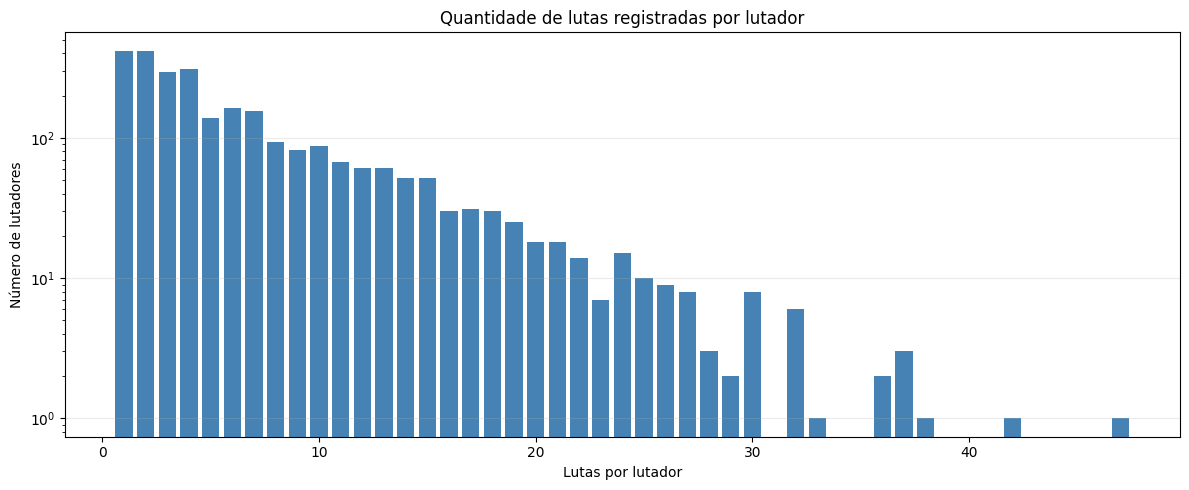

,mínimo_lutas_anteriores,observações_elegíveis,%_observações,lutadores_com_observação_elegível,%_lutadores
0,0,17472,100.0,2693,100.0
1,1,14730,84.3,2271,84.3
2,2,12486,71.5,1860,69.1
3,3,10629,60.8,1564,58.1
4,4,9064,51.9,1255,46.6
5,5,7813,44.7,1117,41.5
6,8,4939,28.3,704,26.1
7,10,3616,20.7,536,19.9


In [66]:
colunas_necessarias = ["fighter_id", "fight_id_hist", "qtd_lutas_anteriores"]
faltando = [col for col in colunas_necessarias if col not in gold_hist.columns]

if faltando:
    raise ValueError(f"Colunas ausentes em gold_hist: {faltando}")

base = gold_hist[colunas_necessarias].copy()

if base[["fighter_id", "fight_id_hist"]].isna().any().any():
    raise ValueError("Há registros sem fighter_id ou fight_id_hist.")

duplicados = base.duplicated(["fighter_id", "fight_id_hist"], keep=False)
if duplicados.any():
    raise ValueError(
        f"Foram encontradas {duplicados.sum()} linhas duplicadas por lutador/luta. "
        "Verifique-as antes de contar as observações."
    )

base["qtd_lutas_anteriores"] = pd.to_numeric(
    base["qtd_lutas_anteriores"], errors="coerce"
)

if base["qtd_lutas_anteriores"].isna().any():
    raise ValueError("qtd_lutas_anteriores contém valores ausentes ou não numéricos.")
 
lutas_por_lutador = (
    base.groupby("fighter_id")["fight_id_hist"]
    .nunique()
    .rename("total_lutas")
)

frequencia = lutas_por_lutador.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(frequencia.index, frequencia.values, color="steelblue")
ax.set_title("Quantidade de lutas registradas por lutador")
ax.set_xlabel("Lutas por lutador")
ax.set_ylabel("Número de lutadores")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
 
total_lutadores = base["fighter_id"].nunique()
total_observacoes = len(base)

limites = [0, 1, 2, 3, 4, 5, 8, 10]
linhas = []

for minimo in limites:
    elegiveis = base.loc[base["qtd_lutas_anteriores"] >= minimo]

    linhas.append({
        "mínimo_lutas_anteriores": minimo,
        "observações_elegíveis": len(elegiveis),
        "%_observações": 100 * len(elegiveis) / total_observacoes,
        "lutadores_com_observação_elegível": elegiveis["fighter_id"].nunique(),
        "%_lutadores": 100 * elegiveis["fighter_id"].nunique() / total_lutadores,
    })

resumo_limites = pd.DataFrame(linhas)
display(resumo_limites.round(1))

In [ ]:
colunas_luta = ["red_fighter_id", "blue_fighter_id", "bout_type"]
colunas_faltando = [
    coluna for coluna in colunas_luta
    if coluna not in gold_fight.columns
]
if colunas_faltando:
    raise ValueError(f"Colunas ausentes em gold_fight: {colunas_faltando}")

colunas_fighter = [
    "fighter_id", "height_cm", "peso_kg", "reach_cm"
]
colunas_faltando = [
    coluna for coluna in colunas_fighter
    if coluna not in gold_fighter.columns
]
if colunas_faltando:
    raise ValueError(f"Colunas ausentes em gold_fighter: {colunas_faltando}")

if gold_fighter["fighter_id"].duplicated().any():
    raise ValueError("gold_fighter possui fighter_id duplicado.")

# Coloca red e blue no mesmo formato: uma linha por atleta/luta.
red = gold_fight[["red_fighter_id", "bout_type"]].rename(
    columns={"red_fighter_id": "fighter_id"}
)
blue = gold_fight[["blue_fighter_id", "bout_type"]].rename(
    columns={"blue_fighter_id": "fighter_id"}
)

participacoes = pd.concat([red, blue], ignore_index=True)
participacoes = participacoes.dropna(
    subset=["fighter_id", "bout_type"]
).copy()

# Padroniza o nome da divisão.
participacoes["categoria"] = (
    participacoes["bout_type"]
    .astype("string")
    .str.replace(r"\s+Bout$", "", regex=True)
    .str.strip()
)

# Infere sexo somente quando a categoria dá evidência suficiente.
categoria_minuscula = participacoes["categoria"].str.lower()

divisoes_conhecidas = (
    "strawweight|flyweight|bantamweight|featherweight|"
    "lightweight|welterweight|middleweight|light heavyweight|heavyweight"
)

feminino = categoria_minuscula.str.contains(
    r"women|woman|female",
    regex=True,
    na=False
)
divisao_reconhecida = categoria_minuscula.str.contains(
    divisoes_conhecidas,
    regex=True,
    na=False
)

participacoes["sexo_inferido"] = pd.NA
participacoes.loc[feminino, "sexo_inferido"] = "Feminino"
participacoes.loc[
    ~feminino & divisao_reconhecida,
    "sexo_inferido"
] = "Masculino"

def moda_ou_na(serie):
    modas = serie.mode()
    return modas.iloc[0] if not modas.empty else pd.NA

perfil_categoria = (
    participacoes.groupby("fighter_id")
    .agg(
        categoria_principal=("categoria", moda_ou_na),
        sexo_inferido=("sexo_inferido", moda_ou_na),
        categorias_distintas=("categoria", "nunique"),
        participacoes=("categoria", "size"),
    )
    .reset_index()
)

# Une a categoria inferida com as medidas do lutador.
base_reach = gold_fighter[colunas_fighter].merge(
    perfil_categoria,
    on="fighter_id",
    how="left",
    validate="one_to_one",
)

for coluna in ["height_cm", "peso_kg", "reach_cm"]:
    base_reach[coluna] = pd.to_numeric(
        base_reach[coluna], errors="coerce"
    )

print("Atletas na dimensão:", len(base_reach))
print("Atletas com categoria vinculada:", base_reach["categoria_principal"].notna().sum())
print("Atletas com categoria variada na carreira:", base_reach["categorias_distintas"].gt(1).sum())
print("Atletas com sexo não inferido:", base_reach["sexo_inferido"].isna().sum())

print("\nCategorias mais frequentes:")
display(base_reach["categoria_principal"].value_counts(dropna=False).head(20))

print("\nResumo de height_cm, peso_kg e reach_cm:")
display(
    base_reach[
        ["height_cm", "peso_kg", "reach_cm"]
    ].describe().round(1)
)

# Avalia altura/reach por sexo e categoria.
com_medidas = base_reach.dropna(
    subset=["height_cm", "reach_cm", "sexo_inferido", "categoria_principal"]
).copy()

resumo_grupos = (
    com_medidas.groupby(
        ["sexo_inferido", "categoria_principal"],
        observed=True
    )
    .agg(
        atletas=("fighter_id", "nunique"),
        altura_media_cm=("height_cm", "mean"),
        reach_medio_cm=("reach_cm", "mean"),
        correlacao_altura_reach=(
            "height_cm",
            lambda altura: altura.corr(
                com_medidas.loc[altura.index, "reach_cm"]
            )
        ),
    )
    .reset_index()
    .sort_values(["sexo_inferido", "categoria_principal"])
)

print("\nRelação entre altura e reach por sexo/categoria:")
display(resumo_grupos.round(2))

Atletas na dimensão: 4524
Atletas com categoria vinculada: 2693
Atletas com categoria variada na carreira: 1057
Atletas com sexo não inferido: 1899

Categorias mais frequentes:


categoria_principal
<NA>                             1831
Lightweight                       441
Welterweight                      394
Middleweight                      345
Bantamweight                      269
Featherweight                     264
Heavyweight                       264
Light Heavyweight                 193
Flyweight                         129
Women's Strawweight               100
Open Weight                        76
Women's Bantamweight               72
Women's Flyweight                  70
Catch Weight                       13
UFC Welterweight Title              7
Women's Featherweight               7
UFC Light Heavyweight Title         6
UFC Middleweight Title              5
UFC Heavyweight Title               3
UFC Women's Strawweight Title       3
Name: count, dtype: Int64


Resumo de height_cm, peso_kg e reach_cm:


,height_cm,peso_kg,reach_cm
count,4287.0,3881.0,2835.0
mean,178.1,76.4,181.7
std,9.0,17.8,10.9
min,139.7,47.6,147.3
25%,172.7,65.8,175.3
50%,177.8,70.3,182.9
75%,185.4,83.9,189.9
max,226.1,349.3,213.4



Relação entre altura e reach por sexo/categoria:


c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\edude\.pyenv\pyenv-win\versions\3.12.1\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,sexo_inferido,categoria_principal,atletas,altura_media_cm,reach_medio_cm,correlacao_altura_reach
0,Feminino,Catch Weight,1,175.26,173.99,NaN
1,Feminino,Road to UFC 3 Women's Strawweight Tournament T...,2,163.83,161.29,1.00
2,Feminino,UFC Women's Bantamweight Title,2,171.45,171.45,1.00
3,Feminino,UFC Women's Featherweight Title,1,172.72,172.72,NaN
4,Feminino,UFC Women's Flyweight Title,2,165.10,166.37,NaN
5,Feminino,UFC Women's Strawweight Title,3,165.10,163.41,0.87
6,Feminino,Ultimate Fighter 18 Women's Bantamweight Tourn...,1,170.18,172.72,NaN
7,Feminino,Women's Bantamweight,71,169.54,170.96,0.65
8,Feminino,Women's Featherweight,7,173.45,176.35,0.57
9,Feminino,Women's Flyweight,70,166.70,168.91,0.61


---------------
### Clusterização 
Porém antes de darmos inicio ao clusterização identificamos alguns casos de nulos em informações que iriamos utilizar: 
- Coluna reach_cm, que tem como objetivo trazer o alcante/envergadura do lutador. 
- Idade do lutador na época da luta

Como pensamos em resolver criando, entender se há relação entre variáveis fisicas e de categoria para tentar realizar um preenchimento (na variavel reach). [não deu certo]

- Iremos preencher inicialmente como indefinido e vamos fazer uma clusterização temporal espansiva.
    - `Que é nada mais que uma clusterização que recebe uma quantidade de registro de calibração temporal, com objetivo de acompanhar a transição sem usar o futuro.`
    - `Definimos de primeira mão mão um perfil de lutador, seria lutadores sem experiência para definição de perfil técnico.`
- Features que iremos utilizar na primeira versão:
    - Dados históricos de lutas anteriores.
    - Dados Fisícos dos atletas
    - Sexo e Categoria

In [155]:
features_antes = [
    "sig_str_min_antes",
    "sig_str_recebidos_min_antes",
    "td_15min_antes",
    "td_tent_15min_antes",
    "sub_15min_antes",
    "rev_15min_antes",
    "kd_15min_antes",
    "ctrl_pct_antes",
    "sig_str_acc_antes",
    "str_def_antes",
    "td_acc_antes",
    "td_def_antes",
]

# Limites exploratórios de exposição mínima para receber perfil técnico.
MIN_LUTAS_ANTES = 3
MIN_MINUTOS_ANTES = 15


# ------------------------------------------------------------
# 1. Validar bases e preparar identificadores
# ------------------------------------------------------------

colunas_obrigatorias = [
    "fighter_id",
    "event_date",
    "qtd_lutas_anteriores",
    "tempo_luta_segundos",
]

faltando = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in gold_hist.columns
]
if faltando:
    raise ValueError(f"Colunas ausentes em gold_hist: {faltando}")

if "fighter_id" not in gold_fighter.columns:
    raise ValueError("gold_fighter não contém fighter_id.")

hist = gold_hist.copy()
cadastro = gold_fighter.copy()

hist["fighter_id"] = (
    hist["fighter_id"].astype("string").str.strip()
)
cadastro["fighter_id"] = (
    cadastro["fighter_id"].astype("string").str.strip()
)

if hist["fighter_id"].isna().any():
    raise ValueError("gold_hist contém fighter_id ausente.")

if cadastro["fighter_id"].isna().any():
    raise ValueError("gold_fighter contém fighter_id ausente.")

if cadastro["fighter_id"].duplicated().any():
    duplicados = cadastro.loc[
        cadastro["fighter_id"].duplicated(keep=False),
        "fighter_id",
    ].unique()

    raise ValueError(
        "gold_fighter contém fighter_id duplicados: "
        f"{duplicados[:10].tolist()}"
    )

hist["event_date"] = pd.to_datetime(
    hist["event_date"],
    errors="coerce",
)
hist["qtd_lutas_anteriores"] = pd.to_numeric(
    hist["qtd_lutas_anteriores"],
    errors="coerce",
)
hist["tempo_luta_segundos"] = pd.to_numeric(
    hist["tempo_luta_segundos"],
    errors="coerce",
)

if hist[
    ["event_date", "qtd_lutas_anteriores", "tempo_luta_segundos"]
].isna().any().any():
    raise ValueError(
        "Há event_date, qtd_lutas_anteriores ou tempo_luta_segundos "
        "ausente ou inválido em gold_hist."
    )

if hist["tempo_luta_segundos"].lt(0).any():
    raise ValueError("gold_hist contém duração negativa.")

# Lutas do mesmo atleta na mesma data são tratadas como um único dia.
hist["event_date"] = hist["event_date"].dt.normalize()


# ------------------------------------------------------------
# 2. Converter métricas e flags, preservando os valores originais
# ------------------------------------------------------------

features_antes_disponiveis = [
    coluna for coluna in features_antes
    if coluna in hist.columns
]

if len(features_antes_disponiveis) < 2:
    raise ValueError(
        "gold_hist precisa ter pelo menos duas métricas _antes disponíveis."
    )

flags_disponiveis = [
    f"{coluna}_sem_dado_antes"
    for coluna in features_antes_disponiveis
    if f"{coluna}_sem_dado_antes" in hist.columns
]

for coluna in features_antes_disponiveis:
    hist[coluna] = pd.to_numeric(
        hist[coluna],
        errors="coerce",
    )

for flag in flags_disponiveis:
    hist[flag] = pd.to_numeric(
        hist[flag],
        errors="coerce",
    )


# ------------------------------------------------------------
# 3. Criar um retrato por lutador e dia
# ------------------------------------------------------------

# Seleciona o retrato mais próximo do início do dia:
# a linha com a menor quantidade de lutas anteriores.
minimo_por_dia = (
    hist.groupby(["fighter_id", "event_date"])["qtd_lutas_anteriores"]
    .transform("min")
)

candidatas = hist.loc[
    hist["qtd_lutas_anteriores"].eq(minimo_por_dia)
].copy()

# Se houver empate, as métricas e flags precisam concordar.
# Sem ordem confiável entre lutas do mesmo dia, não escolhemos arbitrariamente.
colunas_validar_empate = (
    features_antes_disponiveis + flags_disponiveis
)

conflitos = (
    candidatas
    .groupby(["fighter_id", "event_date"])[colunas_validar_empate]
    .nunique(dropna=False)
    .gt(1)
)

dias_com_conflito = conflitos.any(axis=1)

if dias_com_conflito.any():
    exemplos = (
        dias_com_conflito[dias_com_conflito]
        .reset_index()[["fighter_id", "event_date"]]
        .head(10)
    )

    raise ValueError(
        "As métricas pré-luta diferem entre registros empatados no mesmo "
        "lutador-dia. Revise estes casos antes de continuar:\n"
        f"{exemplos.to_string(index=False)}"
    )

# Mantém uma linha por lutador-data.
base_cluster_dia = (
    candidatas
    .sort_values(["fighter_id", "event_date"])
    .drop_duplicates(
        subset=["fighter_id", "event_date"],
        keep="first",
    )
    .copy()
)

# Conta quantas linhas/lutas foram reunidas em cada dia.
contagem_dia = (
    hist.groupby(["fighter_id", "event_date"])
    .size()
    .rename("qtd_lutas_no_dia")
    .reset_index()
)

base_cluster_dia = base_cluster_dia.merge(
    contagem_dia,
    on=["fighter_id", "event_date"],
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# 4. Consolidar sexo e categoria observados naquele dia
# ------------------------------------------------------------

coluna_categoria = next(
    (
        coluna for coluna in ["categoria_luta", "bout_type"]
        if coluna in hist.columns
    ),
    None,
)

coluna_sexo = (
    "sexo_luta"
    if "sexo_luta" in hist.columns
    else None
)


def valores_unicos_ou_indef(valores, normalizar_categoria=False):
    conhecidos = valores.dropna().astype("string").str.strip()

    if normalizar_categoria:
        conhecidos = conhecidos.str.replace(
            r"\s+Bout$",
            "",
            regex=True,
        )

    conhecidos = conhecidos[conhecidos.ne("")].unique()

    # Conflitos no mesmo dia ficam explicitamente como indefinidos.
    if len(conhecidos) == 1:
        return conhecidos[0]

    return "indef"


agregacoes_contexto = {}

if coluna_sexo:
    agregacoes_contexto["sexo"] = (
        coluna_sexo,
        valores_unicos_ou_indef,
    )

if coluna_categoria:
    agregacoes_contexto["categoria_luta"] = (
        coluna_categoria,
        lambda valores: valores_unicos_ou_indef(
            valores,
            normalizar_categoria=True,
        ),
    )

if agregacoes_contexto:
    contexto_dia = (
        hist.groupby(["fighter_id", "event_date"])
        .agg(**agregacoes_contexto)
        .reset_index()
    )

    base_cluster_dia = base_cluster_dia.merge(
        contexto_dia,
        on=["fighter_id", "event_date"],
        how="left",
        validate="one_to_one",
    )


# ------------------------------------------------------------
# 5. Calcular minutos de luta acumulados antes de cada dia
# ------------------------------------------------------------

# Soma a duração das lutas do atleta no mesmo dia.
duracao_diaria = (
    hist.groupby(["fighter_id", "event_date"], as_index=False)
    .agg(
        tempo_luta_dia_segundos=("tempo_luta_segundos", "sum")
    )
    .sort_values(["fighter_id", "event_date"])
)

# Acumula apenas os dias anteriores; não inclui a duração do dia atual.
duracao_diaria["tempo_historico_min_antes"] = (
    duracao_diaria
    .groupby("fighter_id")["tempo_luta_dia_segundos"]
    .transform(lambda serie: serie.cumsum() - serie)
    / 60
)

base_cluster_dia = base_cluster_dia.merge(
    duracao_diaria[
        ["fighter_id", "event_date", "tempo_historico_min_antes"]
    ],
    on=["fighter_id", "event_date"],
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# 6. Adicionar atributos físicos de gold_fighter
# ------------------------------------------------------------

colunas_fisicas = ["fighter_id"]

for coluna in ["height_cm", "reach_cm"]:
    if coluna in cadastro.columns:
        cadastro[coluna] = pd.to_numeric(
            cadastro[coluna],
            errors="coerce",
        )
        colunas_fisicas.append(coluna)

if "peso_kg" in cadastro.columns:
    cadastro["peso_kg"] = pd.to_numeric(
        cadastro["peso_kg"],
        errors="coerce",
    )
    colunas_fisicas.append("peso_kg")

elif "weight_lbs" in cadastro.columns:
    cadastro["peso_kg"] = (
        pd.to_numeric(cadastro["weight_lbs"], errors="coerce")
        * 0.453592
    )
    colunas_fisicas.append("peso_kg")

if len(colunas_fisicas) == 1:
    print(
        "Aviso: gold_fighter não contém height_cm, reach_cm "
        "ou peso reconhecido."
    )

base_cluster_dia = base_cluster_dia.merge(
    cadastro[colunas_fisicas],
    on="fighter_id",
    how="left",
    validate="many_to_one",
)


# ------------------------------------------------------------
# 7. Separar sem histórico, histórico curto e elegíveis
# ------------------------------------------------------------

# Estreante: nenhuma luta anterior ao dia atual.
base_cluster_dia["sem_historico"] = (
    base_cluster_dia["qtd_lutas_anteriores"].eq(0)
)

# Elegível ao K-means somente se atingir ambos os limites.
base_cluster_dia["historico_suficiente"] = (
    base_cluster_dia["qtd_lutas_anteriores"].ge(MIN_LUTAS_ANTES)
    & base_cluster_dia["tempo_historico_min_antes"].ge(
        MIN_MINUTOS_ANTES
    )
)

# Já lutou antes, mas ainda não atingiu os critérios de elegibilidade.
base_cluster_dia["historico_curto"] = (
    ~base_cluster_dia["sem_historico"]
    & ~base_cluster_dia["historico_suficiente"]
)

base_cluster_dia["grupo_elegibilidade"] = np.select(
    [
        base_cluster_dia["sem_historico"],
        base_cluster_dia["historico_curto"],
    ],
    [
        "Sem histórico",
        "Histórico curto - perfil inconclusivo",
    ],
    default="Histórico suficiente para clusterização",
)

# Só os dias com histórico suficiente entram no K-means.
base_modelo = base_cluster_dia.loc[
    base_cluster_dia["historico_suficiente"]
].copy()

# Preserva base_cluster_dia. Na cópia de modelagem, converte em NaN
# apenas valores que as flags identificam como sem dado.
for coluna in features_antes_disponiveis:
    indicador = f"{coluna}_sem_dado_antes"

    if indicador in base_modelo.columns:
        sem_dado = base_modelo[indicador].eq(1)
        base_modelo.loc[sem_dado, coluna] = np.nan


# ------------------------------------------------------------
# 8. Verificações e resumo
# ------------------------------------------------------------

if base_cluster_dia.duplicated(
    subset=["fighter_id", "event_date"]
).any():
    raise ValueError(
        "A base ainda contém mais de uma linha por lutador e data."
    )

print("Linhas diárias:", len(base_cluster_dia))
print("Lutadores únicos:", base_cluster_dia["fighter_id"].nunique())
print(
    "Dias com múltiplas lutas consolidadas:",
    int(base_cluster_dia["qtd_lutas_no_dia"].gt(1).sum()),
)
print(
    "Dias sem histórico:",
    int(base_cluster_dia["sem_historico"].sum()),
)
print(
    "Dias com histórico curto:",
    int(base_cluster_dia["historico_curto"].sum()),
)
print(
    "Dias elegíveis para K-means:",
    int(base_cluster_dia["historico_suficiente"].sum()),
)
print(
    "Lutadores elegíveis:",
    base_modelo["fighter_id"].nunique(),
)
print("Métricas _antes disponíveis:", features_antes_disponiveis)
print("Flags de ausência disponíveis:", flags_disponiveis)

display(
    base_cluster_dia["grupo_elegibilidade"]
    .value_counts()
    .rename_axis("grupo")
    .to_frame("dias")
)

colunas_exemplo = [
    "fighter_id",
    "event_date",
    "qtd_lutas_anteriores",
    "tempo_historico_min_antes",
    "qtd_lutas_no_dia",
    "sem_historico",
    "historico_curto",
    "historico_suficiente",
    *features_antes_disponiveis[:2],
]
colunas_exemplo = [
    coluna for coluna in colunas_exemplo
    if coluna in base_cluster_dia.columns
]

display(base_cluster_dia[colunas_exemplo].head(20))

Linhas diárias: 17393
Lutadores únicos: 2693
Dias com múltiplas lutas consolidadas: 57
Dias sem histórico: 2693
Dias com histórico curto: 4285
Dias elegíveis para K-means: 10415
Lutadores elegíveis: 1530
Métricas _antes disponíveis: ['sig_str_min_antes', 'sig_str_recebidos_min_antes', 'td_15min_antes', 'td_tent_15min_antes', 'sub_15min_antes', 'rev_15min_antes', 'kd_15min_antes', 'ctrl_pct_antes', 'sig_str_acc_antes', 'str_def_antes', 'td_acc_antes', 'td_def_antes']
Flags de ausência disponíveis: ['sig_str_min_antes_sem_dado_antes', 'sig_str_recebidos_min_antes_sem_dado_antes', 'td_15min_antes_sem_dado_antes', 'td_tent_15min_antes_sem_dado_antes', 'sub_15min_antes_sem_dado_antes', 'rev_15min_antes_sem_dado_antes', 'kd_15min_antes_sem_dado_antes', 'ctrl_pct_antes_sem_dado_antes', 'sig_str_acc_antes_sem_dado_antes', 'str_def_antes_sem_dado_antes', 'td_acc_antes_sem_dado_antes', 'td_def_antes_sem_dado_antes']


,dias
grupo,
Histórico suficiente para clusterização,10415
Histórico curto - perfil inconclusivo,4285
Sem histórico,2693


,fighter_id,event_date,qtd_lutas_anteriores,tempo_historico_min_antes,qtd_lutas_no_dia,sem_historico,historico_curto,historico_suficiente,sig_str_min_antes,sig_str_recebidos_min_antes
0,001eb2ab0f30e7ea,2025-06-07,0,0.000000,1,True,False,False,0.000000,0.000000
1,002ca196477ce572,2019-07-20,0,0.000000,1,True,False,False,0.000000,0.000000
2,002ca196477ce572,2020-02-29,1,15.000000,1,False,True,False,0.533333,1.000000
3,003d82fa384ca1d0,2020-02-29,0,0.000000,1,True,False,False,0.000000,0.000000
4,003d82fa384ca1d0,2021-03-06,1,1.416667,1,False,True,False,1.411765,14.117647
5,0052de90691d4a93,2017-03-11,0,0.000000,1,True,False,False,0.000000,0.000000
6,0052de90691d4a93,2017-12-09,1,15.000000,1,False,True,False,2.333333,2.600000
7,0052de90691d4a93,2018-05-12,2,25.833333,1,False,True,False,3.483871,3.290323
8,0052de90691d4a93,2018-11-10,3,30.083333,1,False,False,True,3.191136,2.858726
9,0052de90691d4a93,2019-05-18,4,32.033333,1,False,False,True,3.121748,2.715921


Fim da calibração: 2010-09-15
Dias elegíveis na calibração: 1163
Lutadores na calibração: 246


,k,inercia_ponderada,silhouette_1_lutador
0,2,3756.543,0.116
1,3,3441.800,0.101
2,4,3234.061,0.098
3,5,3070.375,0.100
4,6,2932.394,0.084
5,7,2807.110,0.094
6,8,2707.228,0.092


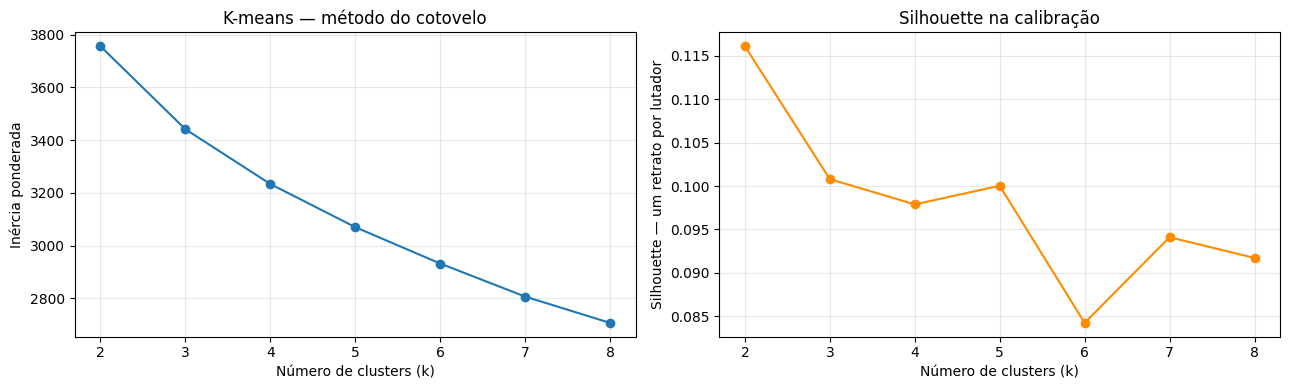

k sugerido para a etapa temporal: 2


In [157]:

# ------------------------------------------------------------
# 1. Preparar os dias elegíveis para a clusterização
# ------------------------------------------------------------

dados_modelo = base_modelo.copy()

dados_modelo["fighter_id"] = (
    dados_modelo["fighter_id"].astype("string").str.strip()
)
dados_modelo["event_date"] = pd.to_datetime(
    dados_modelo["event_date"],
    errors="coerce",
).dt.normalize()

if dados_modelo[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError("Há fighter_id ou event_date ausente em base_modelo.")

# Ordenar garante que a calibração fique em ordem cronológica
dados_modelo = (
    dados_modelo
    .sort_values(["event_date", "fighter_id"])
    .reset_index(drop=True)
)

# Variáveis numéricas candidatas
features_numericas_candidatas = [
    *features_antes_disponiveis,
    "qtd_lutas_anteriores",
    "height_cm",
    "peso_kg",
    "reach_cm",
]

features_numericas_candidatas = [
    coluna for coluna in features_numericas_candidatas
    if coluna in dados_modelo.columns
]

# Sexo e categoria são codificados como variáveis categóricas
features_categoricas = [
    coluna for coluna in ["sexo", "categoria_luta"]
    if coluna in dados_modelo.columns
]

if not features_numericas_candidatas and not features_categoricas:
    raise ValueError("Não há variáveis disponíveis para o K-means.")

# ------------------------------------------------------------
# 2. Definir o período inicial de calibração
# ------------------------------------------------------------

datas_disponiveis = np.sort(
    dados_modelo["event_date"].dropna().unique()
)

if len(datas_disponiveis) < 3:
    raise ValueError(
        "Há poucas datas elegíveis para calibrar e avaliar o modelo."
    )

# Primeiras 20% das datas elegíveis, não 20% de todas as linhas da base
qtd_datas_calibracao = math.ceil(len(datas_disponiveis) * 0.20)
qtd_datas_calibracao = max(2, qtd_datas_calibracao)
qtd_datas_calibracao = min(
    qtd_datas_calibracao,
    len(datas_disponiveis) - 1,
)

data_fim_calibracao = pd.Timestamp(
    datas_disponiveis[qtd_datas_calibracao - 1]
)

calibracao = dados_modelo.loc[
    dados_modelo["event_date"] <= data_fim_calibracao
].copy()

if calibracao.empty:
    raise ValueError("O período de calibração não contém observações.")

print("Fim da calibração:", data_fim_calibracao.date())
print("Dias elegíveis na calibração:", len(calibracao))
print("Lutadores na calibração:", calibracao["fighter_id"].nunique())

# ------------------------------------------------------------
# 3. Preparar variáveis numéricas usando apenas a calibração
# ------------------------------------------------------------

# Descarta variáveis numéricas sem valores observados na calibração
features_numericas = [
    coluna
    for coluna in features_numericas_candidatas
    if pd.to_numeric(
        calibracao[coluna],
        errors="coerce",
    ).notna().any()
]

features_sem_valor_inicial = [
    coluna
    for coluna in features_numericas_candidatas
    if coluna not in features_numericas
]

if features_sem_valor_inicial:
    print(
        "Variáveis numéricas excluídas por não terem valores "
        "na calibração:",
        features_sem_valor_inicial,
    )

X_calibracao_partes = []

if features_numericas:
    imputador = SimpleImputer(strategy="median")

    X_calibracao_numerico = imputador.fit_transform(
        calibracao[features_numericas].apply(
            pd.to_numeric,
            errors="coerce",
        )
    )

    escalador = StandardScaler()
    X_calibracao_numerico = escalador.fit_transform(
        X_calibracao_numerico
    )

    X_calibracao_partes.append(X_calibracao_numerico)

# ------------------------------------------------------------
# 4. Codificar sexo/categoria usando apenas a calibração
# ------------------------------------------------------------

categorias_por_coluna = {}

for coluna in features_categoricas:
    valores = (
        calibracao[coluna]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("indef")
    )

    niveis = sorted(valores.unique().tolist())

    if "__desconhecido__" not in niveis:
        niveis.append("__desconhecido__")

    categorias_por_coluna[coluna] = niveis


def codificar_categorias(df):
    partes = []

    for coluna in features_categoricas:
        if coluna in df.columns:
            valores = (
                df[coluna]
                .astype("string")
                .str.strip()
                .replace("", pd.NA)
                .fillna("indef")
            )
        else:
            valores = pd.Series(
                "indef",
                index=df.index,
                dtype="string",
            )

        niveis = categorias_por_coluna[coluna]
        niveis_conhecidos = [
            nivel for nivel in niveis
            if nivel != "__desconhecido__"
        ]

        valores = valores.where(
            valores.isin(niveis_conhecidos),
            "__desconhecido__",
        )

        categorico = pd.Series(
            pd.Categorical(valores, categories=niveis),
            index=df.index,
        )

        dummies = pd.get_dummies(
            categorico,
            prefix=coluna,
            dtype=float,
        )

        dummies = dummies.reindex(
            columns=[f"{coluna}_{nivel}" for nivel in niveis],
            fill_value=0,
        )

        partes.append(dummies.to_numpy(dtype=float))

    if not partes:
        return np.empty((len(df), 0))

    return np.column_stack(partes)


X_calibracao_categorico = codificar_categorias(calibracao)

if X_calibracao_categorico.shape[1] > 0:
    X_calibracao_partes.append(X_calibracao_categorico)

if not X_calibracao_partes:
    raise ValueError(
        "Não foi possível montar variáveis para o K-means."
    )

X_calibracao = np.column_stack(X_calibracao_partes)

# ------------------------------------------------------------
# 5. Dar peso total igual a cada lutador
# ------------------------------------------------------------

contagem_por_lutador = calibracao["fighter_id"].value_counts()

pesos_calibracao = (
    1 / calibracao["fighter_id"].map(contagem_por_lutador)
).to_numpy(dtype=float)

# Para avaliar silhouette, usa o retrato mais recente de cada lutador
# disponível até o fim da calibração.

mascara_representativas = ~calibracao["fighter_id"].duplicated(
    keep="last"
).to_numpy()

posicoes_representativas = np.flatnonzero(mascara_representativas)
X_representativo = X_calibracao[posicoes_representativas]

if len(X_representativo) < 4:
    raise ValueError(
        "Há menos de quatro lutadores na calibração para comparar valores de k."
    )

# ------------------------------------------------------------
# 6. Avaliar valores de k
# ------------------------------------------------------------

k_max = min(8, len(X_representativo) - 1)
resultados_k = []

for k in range(2, k_max + 1):
    modelo_teste = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    modelo_teste.fit(
        X_calibracao,
        sample_weight=pesos_calibracao,
    )

    rotulos_representativos = modelo_teste.predict(X_representativo)

    if len(np.unique(rotulos_representativos)) < 2:
        silhouette = np.nan
    else:
        silhouette = silhouette_score(
            X_representativo,
            rotulos_representativos,
            sample_size=min(3000, len(X_representativo)),
            random_state=42,
        )

    resultados_k.append({
        "k": k,
        "inercia_ponderada": modelo_teste.inertia_,
        "silhouette_1_lutador": silhouette,
    })

avaliacao_k_temporal = pd.DataFrame(resultados_k)

if avaliacao_k_temporal.empty:
    raise ValueError("Não foi possível avaliar nenhum valor de k.")

display(avaliacao_k_temporal.round(3))

# ------------------------------------------------------------
# 7. Gráficos do cotovelo e silhouette
# ------------------------------------------------------------

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].plot(
    avaliacao_k_temporal["k"],
    avaliacao_k_temporal["inercia_ponderada"],
    marker="o",
)
eixos[0].set_title("K-means — método do cotovelo")
eixos[0].set_xlabel("Número de clusters (k)")
eixos[0].set_ylabel("Inércia ponderada")
eixos[0].set_xticks(avaliacao_k_temporal["k"])
eixos[0].grid(alpha=0.3)

eixos[1].plot(
    avaliacao_k_temporal["k"],
    avaliacao_k_temporal["silhouette_1_lutador"],
    marker="o",
    color="darkorange",
)
eixos[1].set_title("Silhouette na calibração")
eixos[1].set_xlabel("Número de clusters (k)")
eixos[1].set_ylabel("Silhouette — um retrato por lutador")
eixos[1].set_xticks(avaliacao_k_temporal["k"])
eixos[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Sugestão inicial pelo maior silhouette.
# Confira também o cotovelo e a interpretabilidade dos grupos.
avaliacao_valida = avaliacao_k_temporal.dropna(
    subset=["silhouette_1_lutador"]
)

if avaliacao_valida.empty:
    raise ValueError("Não foi possível calcular silhouette para nenhum k.")

k_sugerido = int(
    avaliacao_valida.loc[
        avaliacao_valida["silhouette_1_lutador"].idxmax(),
        "k",
    ]
)

k_escolhido = k_sugerido

print(f"k sugerido para a etapa temporal: {k_escolhido}")

In [159]:
# ------------------------------------------------------------
# 1. Validar dados e objetos criados na célula anterior
# ------------------------------------------------------------

if k_escolhido < 2:
    raise ValueError("k_escolhido precisa ser pelo menos 2.")

dados_modelo = base_modelo.copy()
dados_modelo["fighter_id"] = (
    dados_modelo["fighter_id"].astype("string").str.strip()
)
dados_modelo["event_date"] = pd.to_datetime(
    dados_modelo["event_date"],
    errors="coerce",
).dt.normalize()

if dados_modelo[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError("Há fighter_id ou event_date ausente em base_modelo.")

if dados_modelo.empty:
    raise ValueError("base_modelo está vazia.")

if len(dados_modelo) < k_escolhido:
    raise ValueError(
        "Há menos linhas elegíveis para modelagem do que clusters escolhidos."
    )

if X_calibracao.shape[0] != len(calibracao):
    raise ValueError(
        "O número de linhas de X_calibracao não corresponde a calibracao. "
        "Reexecute a célula de preparação e seleção de k."
    )

if len(pesos_calibracao) != len(calibracao):
    raise ValueError(
        "pesos_calibracao não corresponde ao número de linhas de calibracao."
    )

if calibracao["fighter_id"].nunique() < k_escolhido:
    raise ValueError(
        "A calibração contém menos lutadores únicos do que k_escolhido."
    )


# ------------------------------------------------------------
# 2. Ajuste inicial usando somente o período de calibração
# ------------------------------------------------------------

modelo_temporal = KMeans(
    n_clusters=k_escolhido,
    random_state=42,
    n_init=20,
)

modelo_temporal.fit(
    X_calibracao,
    sample_weight=pesos_calibracao,
)

centros_alinhados = modelo_temporal.cluster_centers_.copy()


# ------------------------------------------------------------
# 3. Inicializar os resultados e estados
# ------------------------------------------------------------

resultado_temporal = base_cluster_dia.copy()

resultado_temporal["fighter_id"] = (
    resultado_temporal["fighter_id"].astype("string").str.strip()
)
resultado_temporal["event_date"] = pd.to_datetime(
    resultado_temporal["event_date"],
    errors="coerce",
).dt.normalize()

if resultado_temporal[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em base_cluster_dia."
    )

if "historico_suficiente" not in resultado_temporal.columns:
    raise ValueError(
        "base_cluster_dia não contém historico_suficiente."
    )

if "historico_curto" not in resultado_temporal.columns:
    raise ValueError(
        "base_cluster_dia não contém historico_curto."
    )

if "sem_historico" not in resultado_temporal.columns:
    resultado_temporal["sem_historico"] = (
        pd.to_numeric(
            resultado_temporal["qtd_lutas_anteriores"],
            errors="coerce",
        ).eq(0)
    )

resultado_temporal["cluster_temporal"] = pd.Series(
    pd.NA,
    index=resultado_temporal.index,
    dtype="Int64",
)

# Estreantes e histórico curto compartilham o mesmo código.
inconclusivo = ~resultado_temporal["historico_suficiente"]

resultado_temporal.loc[
    inconclusivo,
    "cluster_temporal",
] = -2

# -1: sem histórico; -2: histórico curto.
resultado_temporal.loc[
    resultado_temporal["sem_historico"],
    "cluster_temporal",
] = -1

resultado_temporal.loc[
    resultado_temporal["historico_curto"],
    "cluster_temporal",
] = -2

# Dias elegíveis posteriores à calibração serão classificados temporalmente.
datas_para_classificar = sorted(
    resultado_temporal.loc[
        (resultado_temporal["event_date"] > data_fim_calibracao)
        & resultado_temporal["historico_suficiente"],
        "event_date",
    ].dropna().unique()
)


# ------------------------------------------------------------
# 4. Reajustar com o passado e classificar cada dia
# ------------------------------------------------------------

for data_atual in datas_para_classificar:
    data_atual = pd.Timestamp(data_atual)

    # Somente observações elegíveis em datas anteriores entram no ajuste.
    treino_passado = dados_modelo.loc[
        dados_modelo["event_date"] < data_atual
    ].copy()

    linhas_atual = resultado_temporal.index[
        resultado_temporal["event_date"].eq(data_atual)
        & resultado_temporal["historico_suficiente"]
    ]

    if len(linhas_atual) == 0:
        continue

    if (
        treino_passado["fighter_id"].nunique() < k_escolhido
        or len(treino_passado) < k_escolhido
    ):
        raise ValueError(
            f"Histórico anterior insuficiente para ajustar k={k_escolhido} "
            f"em {data_atual.date()}."
        )

    # Aplica imputação e escala ajustadas no período de calibração.
    X_treino_numerico = imputador.transform(
        treino_passado[features_numericas].apply(
            pd.to_numeric,
            errors="coerce",
        )
    )
    X_treino_numerico = escalador.transform(X_treino_numerico)

    X_treino_categorico = codificar_categorias(treino_passado)

    X_treino = np.column_stack([
        X_treino_numerico,
        X_treino_categorico,
    ])

    # Cada lutador tem peso total 1 no ajuste, evitando que carreiras
    # com mais observações dominem apenas pelo número de linhas.
    contagem_por_lutador = treino_passado["fighter_id"].value_counts()

    pesos_passado = (
        1 / treino_passado["fighter_id"].map(contagem_por_lutador)
    ).to_numpy(dtype=float)

    # Reajusta o K-means usando somente o passado até a véspera do dia.
    modelo_atual = KMeans(
        n_clusters=k_escolhido,
        init=centros_alinhados,
        n_init=1,
        max_iter=100,
        random_state=42,
    )

    modelo_atual.fit(
        X_treino,
        sample_weight=pesos_passado,
    )

    # Alinha os rótulos novos aos centróides anteriores para reduzir
    # trocas arbitrárias entre Perfil 0, Perfil 1 etc.
    distancias = cdist(
        centros_alinhados,
        modelo_atual.cluster_centers_,
        metric="euclidean",
    )

    indices_anteriores, indices_atuais = linear_sum_assignment(distancias)

    mapa_rotulos = np.empty(k_escolhido, dtype=int)
    mapa_rotulos[indices_atuais] = indices_anteriores

    centros_novos_alinhados = np.empty_like(
        modelo_atual.cluster_centers_
    )
    centros_novos_alinhados[indices_anteriores] = (
        modelo_atual.cluster_centers_[indices_atuais]
    )

    # Transforma e classifica os retratos elegíveis deste dia.
    linhas_df = resultado_temporal.loc[linhas_atual]

    X_dia_numerico = imputador.transform(
        linhas_df[features_numericas].apply(
            pd.to_numeric,
            errors="coerce",
        )
    )
    X_dia_numerico = escalador.transform(X_dia_numerico)

    X_dia_categorico = codificar_categorias(linhas_df)

    X_dia = np.column_stack([
        X_dia_numerico,
        X_dia_categorico,
    ])

    rotulos_brutos = modelo_atual.predict(X_dia)
    rotulos_alinhados = mapa_rotulos[rotulos_brutos]

    resultado_temporal.loc[
        linhas_atual,
        "cluster_temporal",
    ] = rotulos_alinhados

    centros_alinhados = centros_novos_alinhados


# ------------------------------------------------------------
# 5. Criar rótulos legíveis
# ------------------------------------------------------------

resultado_temporal["grupo_temporal"] = pd.Series(
    pd.NA,
    index=resultado_temporal.index,
    dtype="string",
)

# Estreantes + histórico curto em um grupo único
resultado_temporal.loc[
    inconclusivo,
    "grupo_temporal",
] = "Perfil inconclusivo"

# Linhas elegíveis usadas para iniciar os perfis
em_calibracao = (
    resultado_temporal["historico_suficiente"]
    & resultado_temporal["event_date"].le(data_fim_calibracao)
)

resultado_temporal.loc[
    em_calibracao,
    "grupo_temporal",
] = "Calibração - não classificado"

# Perfis atribuídos pelo K-means após a calibração
tem_perfil = resultado_temporal["cluster_temporal"].ge(0)

resultado_temporal.loc[
    tem_perfil,
    "grupo_temporal",
] = (
    "Perfil "
    + resultado_temporal.loc[tem_perfil, "cluster_temporal"]
    .astype(int)
    .astype(str)
)

# Dias elegíveis até a data final da calibração ficam sem perfil temporal.
em_calibracao = (
    resultado_temporal["historico_suficiente"]
    & resultado_temporal["event_date"].le(data_fim_calibracao)
)

resultado_temporal.loc[
    em_calibracao,
    "grupo_temporal",
] = "Calibração - não classificado"

# Não deixar dias elegíveis posteriores sem classificação silenciosamente.
sem_classificacao_depois = (
    resultado_temporal["historico_suficiente"]
    & resultado_temporal["event_date"].gt(data_fim_calibracao)
    & resultado_temporal["cluster_temporal"].isna()
)

if sem_classificacao_depois.any():
    exemplos = resultado_temporal.loc[
        sem_classificacao_depois,
        ["fighter_id", "event_date"],
    ].head(10)

    raise ValueError(
        "Há dias elegíveis posteriores à calibração sem cluster:\n"
        f"{exemplos.to_string(index=False)}"
    )


# ------------------------------------------------------------
# 6. Conferir distribuição e resultado
# ------------------------------------------------------------

print("Fim da calibração:", data_fim_calibracao.date())
print("Total de dias lutador-data:", len(resultado_temporal))
print("Dias classificados em perfis técnicos:", int(tem_perfil.sum()))
print(
    "Lutadores que receberam perfil técnico:",
    resultado_temporal.loc[tem_perfil, "fighter_id"].nunique(),
)

print("Distribuição dos estados e perfis:")
display(
    resultado_temporal["grupo_temporal"]
    .value_counts(dropna=False)
    .rename_axis("grupo")
    .to_frame("dias")
)

display(
    resultado_temporal[
        [
            "fighter_id",
            "event_date",
            "qtd_lutas_anteriores",
            "tempo_historico_min_antes",
            "sem_historico",
            "historico_curto",
            "historico_suficiente",
            "cluster_temporal",
            "grupo_temporal",
        ]
    ].head(20)
)

Fim da calibração: 2010-09-15
Total de dias lutador-data: 17393
Dias classificados em perfis técnicos: 9252
Lutadores que receberam perfil técnico: 1427
Distribuição dos estados e perfis:


,dias
grupo,
Perfil inconclusivo,6978
Perfil 1,5013
Perfil 0,4239
Calibração - não classificado,1163


,fighter_id,event_date,qtd_lutas_anteriores,tempo_historico_min_antes,sem_historico,historico_curto,historico_suficiente,cluster_temporal,grupo_temporal
0,001eb2ab0f30e7ea,2025-06-07,0,0.000000,True,False,False,-1,Perfil inconclusivo
1,002ca196477ce572,2019-07-20,0,0.000000,True,False,False,-1,Perfil inconclusivo
2,002ca196477ce572,2020-02-29,1,15.000000,False,True,False,-2,Perfil inconclusivo
3,003d82fa384ca1d0,2020-02-29,0,0.000000,True,False,False,-1,Perfil inconclusivo
4,003d82fa384ca1d0,2021-03-06,1,1.416667,False,True,False,-2,Perfil inconclusivo
5,0052de90691d4a93,2017-03-11,0,0.000000,True,False,False,-1,Perfil inconclusivo
6,0052de90691d4a93,2017-12-09,1,15.000000,False,True,False,-2,Perfil inconclusivo
7,0052de90691d4a93,2018-05-12,2,25.833333,False,True,False,-2,Perfil inconclusivo
8,0052de90691d4a93,2018-11-10,3,30.083333,False,False,True,1,Perfil 1
9,0052de90691d4a93,2019-05-18,4,32.033333,False,False,True,1,Perfil 1


In [160]:
print("Total de linhas:", len(resultado_temporal))

print("Linhas sem cluster por situação:")
display(
    resultado_temporal
    .groupby("grupo_temporal")
    .agg(
        linhas=("fighter_id", "size"),
        lutadores=("fighter_id", "nunique"),
        primeira_data=("event_date", "min"),
        ultima_data=("event_date", "max"),
    )
)

print("Linhas sem cluster após o fim da calibração:")
display(
    resultado_temporal.loc[
        resultado_temporal["cluster_temporal"].isna()
        & (resultado_temporal["event_date"] > data_fim_calibracao),
        [
            "fighter_id",
            "event_date",
            "qtd_lutas_anteriores",
            "tempo_historico_min_antes",
            "historico_suficiente",
        ],
    ].head(20)
)

Total de linhas: 17393
Linhas sem cluster por situação:


,linhas,lutadores,primeira_data,ultima_data
grupo_temporal,,,,
Calibração - não classificado,1163,246,1995-04-07,2010-09-15
Perfil 0,4239,666,2010-09-25,2026-06-27
Perfil 1,5013,917,2010-09-25,2026-06-27
Perfil inconclusivo,6978,2693,1994-03-11,2026-06-27


Linhas sem cluster após o fim da calibração:


,fighter_id,event_date,qtd_lutas_anteriores,tempo_historico_min_antes,historico_suficiente


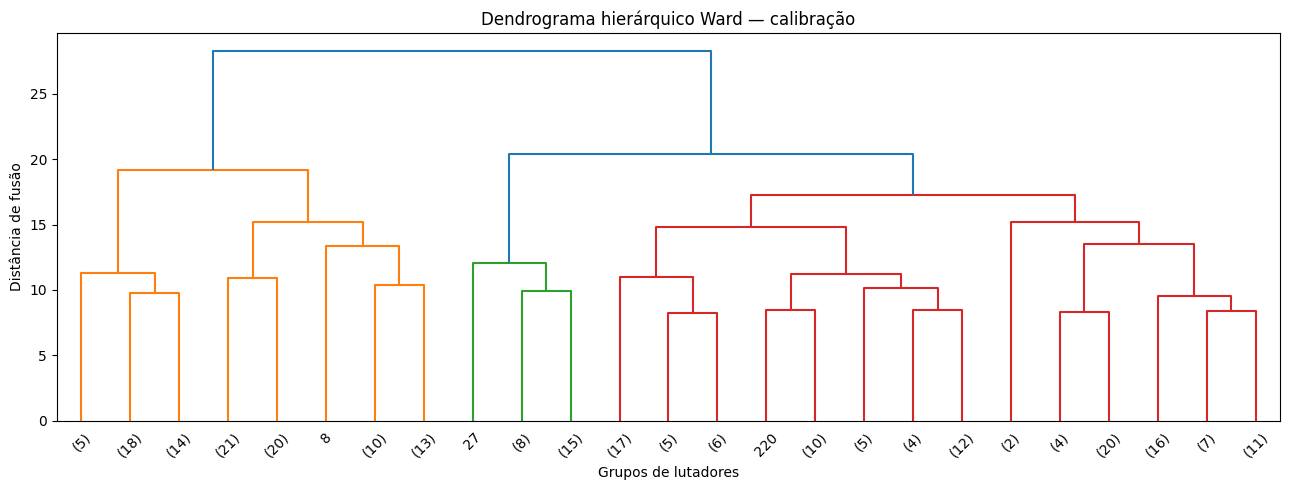

,k,silhouette
0,2,0.098
1,3,0.085
2,4,0.067
3,5,0.067
4,6,0.060
5,7,0.064
6,8,0.070


Grupos hierárquicos na calibração, com k=2:


,lutadores
grupo,
Perfil 0,144
Perfil 1,102


,fighter_id,event_date,cluster_hierarquico,grupo_hierarquico
0,1dc56b59cb28425d,1995-12-16,0,Perfil 0
1,07a18ae55dfc3cd9,1996-12-07,0,Perfil 0
2,271fe91f4ba9d2c5,1996-12-07,0,Perfil 0
3,1c3f5e85b59ec710,1997-07-27,0,Perfil 0
4,93892752c5fc23ca,1999-01-08,0,Perfil 0


In [161]:
posicoes = np.flatnonzero(
    ~calibracao["fighter_id"].duplicated(keep="last").to_numpy()
)

X_hierarquico = X_calibracao[posicoes]
calibracao_hierarquica = (
    calibracao.iloc[posicoes]
    .reset_index(drop=True)
    .copy()
)

if len(X_hierarquico) <= k_escolhido:
    raise ValueError(
        "Há poucos lutadores únicos na calibração para avaliar esse k."
    )

# Hierárquico Ward aplicado aos perfis da calibração
arvore = linkage(X_hierarquico, method="ward")

plt.figure(figsize=(13, 5))
dendrogram(
    arvore,
    truncate_mode="lastp",
    p=25,
    show_leaf_counts=True,
)
plt.title("Dendrograma hierárquico Ward — calibração")
plt.xlabel("Grupos de lutadores")
plt.ylabel("Distância de fusão")
plt.tight_layout()
plt.show()

# Compara silhouette para diferentes números de clusters
resultados_hierarquico = []
k_max_hierarquico = min(8, len(X_hierarquico) - 1)

for k in range(2, k_max_hierarquico + 1):
    rotulos = cut_tree(arvore, n_clusters=k).ravel()

    resultados_hierarquico.append({
        "k": k,
        "silhouette": silhouette_score(
            X_hierarquico,
            rotulos,
            sample_size=min(3000, len(X_hierarquico)),
            random_state=42,
        ),
    })

avaliacao_hierarquico = pd.DataFrame(resultados_hierarquico)
display(avaliacao_hierarquico.round(3))

# Compara o resultado hierárquico com o k escolhido para o K-means
rotulos_hierarquicos_calibracao = cut_tree(
    arvore,
    n_clusters=k_escolhido,
).ravel()

resultado_hierarquico_calibracao = calibracao_hierarquica[
    ["fighter_id", "event_date"]
].copy()

resultado_hierarquico_calibracao["cluster_hierarquico"] = (
    rotulos_hierarquicos_calibracao
)
resultado_hierarquico_calibracao["grupo_hierarquico"] = (
    "Perfil "
    + resultado_hierarquico_calibracao["cluster_hierarquico"].astype(str)
)

print(f"Grupos hierárquicos na calibração, com k={k_escolhido}:")
display(
    resultado_hierarquico_calibracao["grupo_hierarquico"]
    .value_counts()
    .rename_axis("grupo")
    .to_frame("lutadores")
)

display(resultado_hierarquico_calibracao.head())

In [162]:
rotulos_kmeans_calibracao = modelo_temporal.predict(X_hierarquico)

print("Comparação dos agrupamentos na calibração:")
display(
    pd.crosstab(
        pd.Series(rotulos_hierarquicos_calibracao, name="Hierárquico"),
        pd.Series(rotulos_kmeans_calibracao, name="K-means"),
        normalize="index",
    ).round(3)
)

Comparação dos agrupamentos na calibração:


K-means,0,1
Hierárquico,,
0,0.875,0.125
1,0.206,0.794


Variância explicada pelas duas componentes: 34.6%


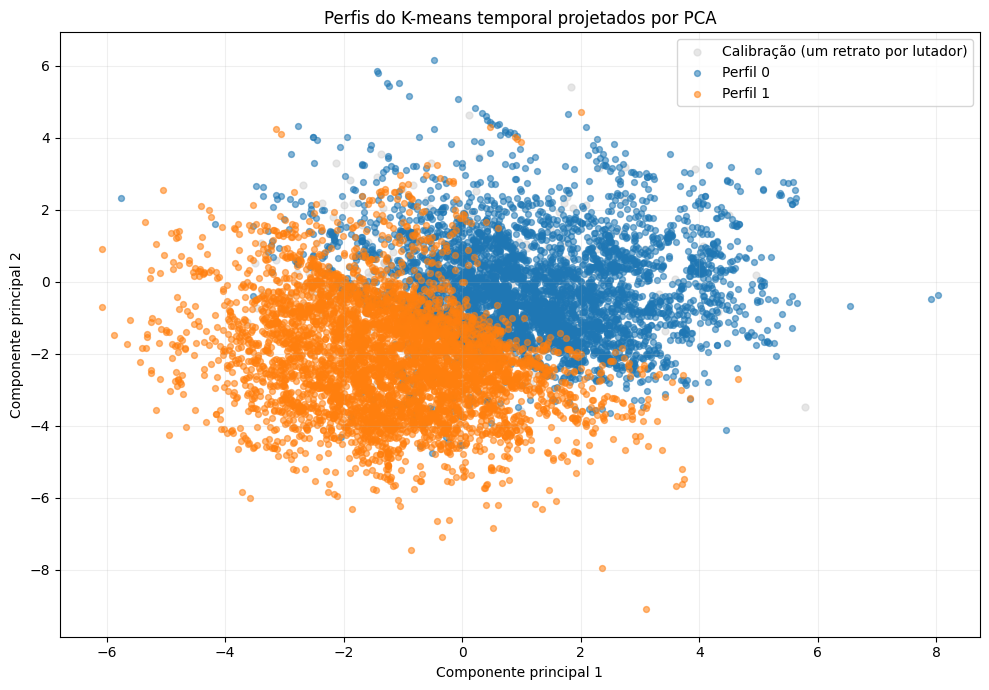

In [164]:

posicoes_calibracao = np.flatnonzero(
    ~calibracao["fighter_id"]
    .duplicated(keep="last")
    .to_numpy()
)

X_calibracao_pca = X_calibracao[posicoes_calibracao]

if min(X_calibracao_pca.shape) < 2:
    raise ValueError(
        "São necessárias pelo menos duas observações e duas variáveis "
        "para projetar os dados em duas componentes."
    )

# Ajusta os eixos do PCA somente nos representantes da calibração
pca = PCA(n_components=2)
pca.fit(X_calibracao_pca)

# Retratos pós-calibração que receberam um perfil técnico
linhas_plot = resultado_temporal.loc[
    resultado_temporal["cluster_temporal"].notna()
    & resultado_temporal["cluster_temporal"].ge(0)
].copy()

if linhas_plot.empty:
    raise ValueError(
        "Não há linhas pós-calibração com perfil técnico para plotar."
    )

# Prepara os dados posteriores com os mesmos transformadores e
# a mesma codificação categórica usados no K-means
X_plot_numerico = imputador.transform(
    linhas_plot[features_numericas].apply(
        pd.to_numeric,
        errors="coerce",
    )
)
X_plot_numerico = escalador.transform(X_plot_numerico)

X_plot_categorico = codificar_categorias(linhas_plot)

X_plot = np.column_stack([
    X_plot_numerico,
    X_plot_categorico,
])

if X_plot.shape[1] != X_calibracao.shape[1]:
    raise ValueError(
        "A matriz dos dados posteriores não tem o mesmo número de "
        "variáveis da calibração."
    )

coordenadas_plot = pca.transform(X_plot)
coordenadas_calibracao = pca.transform(X_calibracao_pca)

print(
    "Variância explicada pelas duas componentes:",
    f"{pca.explained_variance_ratio_.sum():.1%}",
)

# Mostra a calibração como referência neutra e os perfis posteriores
# com cores distintas.
plt.figure(figsize=(10, 7))

plt.scatter(
    coordenadas_calibracao[:, 0],
    coordenadas_calibracao[:, 1],
    color="lightgray",
    alpha=0.55,
    s=24,
    label="Calibração (um retrato por lutador)",
)

rotulos_presentes = sorted(
    linhas_plot["cluster_temporal"].astype(int).unique()
)

for rotulo in rotulos_presentes:
    mascara = linhas_plot["cluster_temporal"].astype(int).eq(rotulo)

    plt.scatter(
        coordenadas_plot[mascara.to_numpy(), 0],
        coordenadas_plot[mascara.to_numpy(), 1],
        alpha=0.55,
        s=18,
        label=f"Perfil {rotulo}",
    )

plt.title("Perfis do K-means temporal projetados por PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

### Resultado da clusterização temporal

A expectativa inicial era identificar diferentes perfis estratégicos a partir do histórico dos lutadores. Com as variáveis, os critérios de elegibilidade e o método utilizados nesta análise, foram identificados dois perfis técnicos. Os rótulos abaixo são interpretações provisórias e devem ser entendidos junto às métricas que caracterizam cada grupo.

- **Perfil inconclusivo:** observações de estreantes ou de lutadores que ainda não atingiram o mínimo definido para atribuição de um perfil técnico — pelo menos 3 lutas anteriores e 15 minutos acumulados de combate.
- **Perfil 0 — possível predominância de trocação (interpretação provisória):** hipótese a ser sustentada pelas métricas técnicas do grupo.
- **Perfil 1 — possível predominância de grappling (interpretação provisória):** hipótese a ser sustentada pelas métricas técnicas do grupo.
- **Calibração — sem perfil atribuído:** período inicial usado para estabelecer os perfis de referência. Essas observações não são um cluster técnico e não entram na análise de transições temporais.

Na execução atual, a base contém 17.393 observações lutador-data: 4.239 classificadas como Perfil 0, 5.013 como Perfil 1, 6.978 como inconclusivas e 1.163 no período de calibração. Assim, a calibração representa aproximadamente 6,7% das observações, não 6% dos lutadores únicos.

Os perfis são atribuídos ao longo do tempo com base nas informações disponíveis antes de cada data. As transições indicam mudanças de atribuição entre os perfis do modelo; por si só, não comprovam uma mudança definitiva de estratégia do lutador.

In [108]:
# Faz uma cópia para preservar a gold_hist original
gold_hist_clusterizado = gold_hist.copy()
gold_hist_clusterizado["fighter_id"] = (
    gold_hist_clusterizado["fighter_id"]
    .astype("string")
    .str.strip()
)

# Alinha o índice dos perfis ao formato do fighter_id da gold_hist
perfis_lookup = perfis.copy()
perfis_lookup.index = perfis_lookup.index.astype("string")

# Confere se todas as variáveis usadas no treino estão disponíveis
colunas_faltando = [
    coluna for coluna in features_numericas
    if coluna not in gold_hist_clusterizado.columns
    and coluna not in perfis_lookup.columns
]
if colunas_faltando:
    raise ValueError(
        f"Variáveis numéricas não encontradas para classificar as linhas: "
        f"{colunas_faltando}"
    )

if "qtd_lutas_anteriores" not in gold_hist_clusterizado.columns:
    raise ValueError("gold_hist não contém qtd_lutas_anteriores.")

# Monta a matriz numérica de cada linha:
# usa os valores da luta para as variáveis presentes em gold_hist;
# atributos estáticos ausentes na gold_hist vêm do perfil do lutador.
X_linhas_numericas = pd.DataFrame(
    index=gold_hist_clusterizado.index,
    columns=features_numericas,
)

for coluna in features_numericas:
    if coluna in gold_hist_clusterizado.columns:
        X_linhas_numericas[coluna] = gold_hist_clusterizado[coluna]
    else:
        X_linhas_numericas[coluna] = (
            gold_hist_clusterizado["fighter_id"]
            .map(perfis_lookup[coluna])
        )

# Converte para números e preserva ausências sinalizadas nos indicadores
for coluna in features_numericas:
    X_linhas_numericas[coluna] = pd.to_numeric(
        X_linhas_numericas[coluna],
        errors="coerce",
    )

    indicador = f"{coluna}_sem_dado_antes"
    if indicador in gold_hist_clusterizado.columns:
        sem_dado = pd.to_numeric(
            gold_hist_clusterizado[indicador],
            errors="coerce",
        ).eq(1)

        X_linhas_numericas.loc[sem_dado, coluna] = np.nan

# Aplica os mesmos transformadores usados no treinamento
X_linhas_numericas = imputador.transform(X_linhas_numericas)
X_linhas_numericas = escalador.transform(X_linhas_numericas)

# Recupera sexo e categoria principal consolidados por lutador
sexo_linha = (
    gold_hist_clusterizado["fighter_id"]
    .map(perfis_lookup["sexo"])
    .astype("string")
    .fillna("indef")
)

categoria_linha = (
    gold_hist_clusterizado["fighter_id"]
    .map(perfis_lookup["categoria_principal"])
    .astype("string")
    .fillna("indef")
)

# Codifica categorias usando exatamente as colunas do treinamento
X_sexo_linhas = pd.get_dummies(
    sexo_linha,
    prefix="sexo",
    dtype=float,
).reindex(columns=X_sexo.columns, fill_value=0)

X_categoria_linhas = pd.get_dummies(
    categoria_linha,
    prefix="categoria",
    dtype=float,
).reindex(columns=X_categoria.columns, fill_value=0)

# Combina na mesma ordem usada para treinar o K-means
X_linhas = np.column_stack([
    X_linhas_numericas,
    X_sexo_linhas.to_numpy(),
    X_categoria_linhas.to_numpy(),
])

# Sem histórico prévio: grupo separado de estreantes.
# As demais linhas são atribuídas ao centróide mais próximo.
qtd_anteriores = pd.to_numeric(
    gold_hist_clusterizado["qtd_lutas_anteriores"],
    errors="coerce",
)

if qtd_anteriores.isna().any():
    raise ValueError(
        "Há qtd_lutas_anteriores ausente; revise antes de atribuir clusters."
    )

estreante = qtd_anteriores.eq(0)
gold_hist_clusterizado["cluster"] = -1

gold_hist_clusterizado.loc[~estreante, "cluster"] = (
    modelo_kmeans.predict(X_linhas[~estreante.to_numpy()])
)

gold_hist_clusterizado["grupo"] = np.where(
    estreante,
    "Estreante - sem histórico prévio observado",
    "Perfil " + gold_hist_clusterizado["cluster"].astype(str),
)

print("Quantidade de linhas por grupo:")
display(
    gold_hist_clusterizado["grupo"]
    .value_counts()
    .rename_axis("grupo")
    .to_frame("linhas")
)

print("Lutadores únicos por grupo:")
display(
    gold_hist_clusterizado
    .groupby("grupo")["fighter_id"]
    .nunique()
    .rename("lutadores")
    .to_frame()
)

Quantidade de linhas por grupo:


,linhas
grupo,
Perfil 0,8875
Perfil 1,5855
Estreante - sem histórico prévio observado,2742


Lutadores únicos por grupo:


,lutadores
grupo,
Estreante - sem histórico prévio observado,2693
Perfil 0,1782
Perfil 1,1152


In [165]:
# 1. Preparar os rótulos temporais por lutador e dia
# ------------------------------------------------------------

colunas_resultado = [
    "fighter_id",
    "event_date",
    "cluster_temporal",
    "grupo_temporal",
]

faltando = [
    coluna for coluna in colunas_resultado
    if coluna not in resultado_temporal.columns
]
if faltando:
    raise ValueError(
        f"Colunas ausentes em resultado_temporal: {faltando}"
    )

rotulos_dia = resultado_temporal[colunas_resultado].copy()

rotulos_dia["fighter_id"] = (
    rotulos_dia["fighter_id"].astype("string").str.strip()
)
rotulos_dia["event_date"] = pd.to_datetime(
    rotulos_dia["event_date"],
    errors="coerce",
).dt.normalize()
rotulos_dia["cluster_temporal"] = pd.to_numeric(
    rotulos_dia["cluster_temporal"],
    errors="coerce",
).astype("Int64")

if rotulos_dia[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em resultado_temporal."
    )

if rotulos_dia.duplicated(["fighter_id", "event_date"]).any():
    raise ValueError(
        "resultado_temporal precisa ter uma linha por fighter_id e data."
    )

# Unifica estreantes (-1) e histórico curto (-2) num único estado.
# Os dois são situações sem perfil técnico disponível.
inconclusivo = rotulos_dia["cluster_temporal"].isin([-1, -2])

rotulos_dia.loc[inconclusivo, "cluster_temporal"] = -2
rotulos_dia.loc[inconclusivo, "grupo_temporal"] = "Perfil inconclusivo"

# Confere se há dias elegíveis posteriores à calibração sem cluster.
# Os estados inconclusivos já foram tratados; cluster nulo restante
# representa a calibração ou uma linha que precisa ser investigada.
if "historico_suficiente" in resultado_temporal.columns:
    suficiente = resultado_temporal["historico_suficiente"].to_numpy()
    depois_calibracao = (
        pd.to_datetime(
            resultado_temporal["event_date"],
            errors="coerce",
        ).dt.normalize()
        > data_fim_calibracao
    ).to_numpy()

    sem_cluster_pos_calibracao = (
        suficiente
        & depois_calibracao
        & rotulos_dia["cluster_temporal"].isna().to_numpy()
    )

    if sem_cluster_pos_calibracao.any():
        raise ValueError(
            "Há dias com histórico suficiente após a calibração, "
            "mas sem cluster atribuído."
        )

# Cluster técnico não nulo deve ter rótulo Perfil N
tem_cluster_tecnico = rotulos_dia["cluster_temporal"].ge(0)
rotulos_dia.loc[tem_cluster_tecnico, "grupo_temporal"] = (
    "Perfil "
    + rotulos_dia.loc[tem_cluster_tecnico, "cluster_temporal"]
    .astype(int)
    .astype(str)
)

# ------------------------------------------------------------
# 2. Calcular transições por lutador-dia
# ------------------------------------------------------------

rotulos_dia = rotulos_dia.sort_values(
    ["fighter_id", "event_date"]
).reset_index(drop=True)

# Estado do dia anterior do mesmo lutador:
# >= 0 = perfil técnico; -2 = inconclusivo; nulo = calibração/sem observação.
rotulos_dia["cluster_anterior"] = (
    rotulos_dia.groupby("fighter_id")["cluster_temporal"]
    .shift(1)
    .astype("Int64")
)

rotulos_dia["grupo_anterior"] = (
    rotulos_dia.groupby("fighter_id")["grupo_temporal"]
    .shift(1)
    .astype("string")
)

cluster_atual = rotulos_dia["cluster_temporal"]
cluster_anterior = rotulos_dia["cluster_anterior"]

# Mudança de perfil significa mudança entre dois perfis técnicos.
rotulos_dia["alterou_perfil_desde_ultima"] = (
    cluster_atual.ge(0)
    & cluster_anterior.ge(0)
    & cluster_atual.ne(cluster_anterior)
).fillna(False)

# Entrada em um perfil técnico depois de uma observação inconclusiva.
rotulos_dia["entrou_em_perfil_tecnico"] = (
    cluster_atual.ge(0)
    & cluster_anterior.eq(-2)
).fillna(False)

# Contagem acumulada de mudanças técnicas, incluindo o dia atual.
rotulos_dia["qtd_transicoes_ate_dia"] = (
    rotulos_dia.groupby("fighter_id")[
        "alterou_perfil_desde_ultima"
    ].cumsum()
)

rotulos_dia["houve_transicao_ate_dia"] = (
    rotulos_dia["qtd_transicoes_ate_dia"] > 0
)

# Também cria uma descrição legível da passagem entre estados.
rotulos_dia["transicao_desde_ultima"] = "sem mudança entre perfis"

primeira_observacao = rotulos_dia["cluster_anterior"].isna()
rotulos_dia.loc[
    primeira_observacao,
    "transicao_desde_ultima",
] = "primeira observação"

mudou = rotulos_dia["alterou_perfil_desde_ultima"]
rotulos_dia.loc[mudou, "transicao_desde_ultima"] = (
    rotulos_dia.loc[mudou, "grupo_anterior"]
    + " -> "
    + rotulos_dia.loc[mudou, "grupo_temporal"]
)

entrou = rotulos_dia["entrou_em_perfil_tecnico"]
rotulos_dia.loc[entrou, "transicao_desde_ultima"] = (
    "Perfil inconclusivo -> "
    + rotulos_dia.loc[entrou, "grupo_temporal"]
)

# ------------------------------------------------------------
# 3. Levar os rótulos diários para cada linha de gold_hist
# ------------------------------------------------------------

historico = gold_hist.copy()

historico["fighter_id"] = (
    historico["fighter_id"].astype("string").str.strip()
)
historico["_event_date_dia"] = pd.to_datetime(
    historico["event_date"],
    errors="coerce",
).dt.normalize()

if historico[["fighter_id", "_event_date_dia"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em gold_hist."
    )

colunas_transicao = [
    "fighter_id",
    "event_date",
    "cluster_temporal",
    "grupo_temporal",
    "cluster_anterior",
    "grupo_anterior",
    "alterou_perfil_desde_ultima",
    "entrou_em_perfil_tecnico",
    "qtd_transicoes_ate_dia",
    "houve_transicao_ate_dia",
    "transicao_desde_ultima",
]

mapa_transicoes = rotulos_dia[colunas_transicao].rename(
    columns={"event_date": "_event_date_dia"}
)

gold_hist_clusterizado = historico.merge(
    mapa_transicoes,
    on=["fighter_id", "_event_date_dia"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

sem_correspondencia = gold_hist_clusterizado["_merge"].ne("both")
if sem_correspondencia.any():
    exemplos = gold_hist_clusterizado.loc[
        sem_correspondencia,
        ["fighter_id", "_event_date_dia"],
    ].head(10)

    raise ValueError(
        "Algumas linhas de gold_hist não encontraram rótulo temporal:\n"
        f"{exemplos.to_string(index=False)}"
    )

gold_hist_clusterizado = gold_hist_clusterizado.drop(
    columns=["_event_date_dia", "_merge"]
)

# ------------------------------------------------------------
# 4. Conferir distribuição e transições
# ------------------------------------------------------------

print("Linhas originais:", len(gold_hist))
print("Linhas com rótulo temporal:", len(gold_hist_clusterizado))
print("\nDistribuição por estado/perfil:")
display(
    rotulos_dia["grupo_temporal"]
    .value_counts(dropna=False)
    .rename_axis("grupo")
    .to_frame("dias")
)

print("\nLutadores únicos por estado/perfil (podem aparecer em vários):")
display(
    rotulos_dia.groupby("grupo_temporal", dropna=False)["fighter_id"]
    .nunique()
    .rename("lutadores")
    .to_frame()
)

print("\nTransições entre perfis técnicos:")
display(
    rotulos_dia.loc[rotulos_dia["alterou_perfil_desde_ultima"]]
    .groupby(["grupo_anterior", "grupo_temporal"])
    .size()
    .rename("quantidade")
    .reset_index()
)

print("\nExemplo da base final:")
display(
    gold_hist_clusterizado[
        [
            "fighter_id",
            "event_date",
            "cluster_temporal",
            "grupo_temporal",
            "cluster_anterior",
            "alterou_perfil_desde_ultima",
            "houve_transicao_ate_dia",
            "transicao_desde_ultima",
        ]
    ].head(20)
)

Linhas originais: 17472
Linhas com rótulo temporal: 17472

Distribuição por estado/perfil:


,dias
grupo,
Perfil inconclusivo,6978
Perfil 1,5013
Perfil 0,4239
Calibração - não classificado,1163



Lutadores únicos por estado/perfil (podem aparecer em vários):


,lutadores
grupo_temporal,
Calibração - não classificado,246
Perfil 0,666
Perfil 1,917
Perfil inconclusivo,2693



Transições entre perfis técnicos:


,grupo_anterior,grupo_temporal,quantidade
0,Perfil 0,Perfil 1,78
1,Perfil 1,Perfil 0,127



Exemplo da base final:


,fighter_id,event_date,cluster_temporal,grupo_temporal,cluster_anterior,alterou_perfil_desde_ultima,houve_transicao_ate_dia,transicao_desde_ultima
0,95aff2fd8d09a5f0,2026-06-27,-2,Perfil inconclusivo,-2,False,False,sem mudança entre perfis
1,36b8f265bcd1b7a4,2026-06-27,0,Perfil 0,0,False,False,sem mudança entre perfis
2,8d3273573b85be09,2026-06-27,1,Perfil 1,1,False,False,sem mudança entre perfis
3,a4dc0f2b95df4cc1,2026-06-27,1,Perfil 1,-2,False,False,Perfil inconclusivo -> Perfil 1
4,70dd69b6a703257e,2026-06-27,-2,Perfil inconclusivo,-2,False,False,sem mudança entre perfis
5,c88f8a9c1ea7165d,2026-06-27,-2,Perfil inconclusivo,<NA>,False,False,primeira observação
6,b07aed698fba8624,2026-06-27,0,Perfil 0,-2,False,False,Perfil inconclusivo -> Perfil 0
7,7facc9c45d792985,2026-06-27,1,Perfil 1,1,False,False,sem mudança entre perfis
8,ff62013d2fce6d13,2026-06-27,1,Perfil 1,1,False,False,sem mudança entre perfis
9,49d2a08964c5eb11,2026-06-27,0,Perfil 0,0,False,False,sem mudança entre perfis


In [168]:

# ------------------------------------------------------------
# 1. Preparar os rótulos temporais, uma linha por lutador-dia
# ------------------------------------------------------------

colunas_rotulos = [
    "fighter_id",
    "event_date",
    "cluster_temporal",
]

faltando = [
    coluna for coluna in colunas_rotulos
    if coluna not in resultado_temporal.columns
]
if faltando:
    raise ValueError(
        f"Colunas ausentes em resultado_temporal: {faltando}"
    )

rotulos_dia = resultado_temporal.copy()

rotulos_dia["fighter_id"] = (
    rotulos_dia["fighter_id"].astype("string").str.strip()
)
rotulos_dia["event_date"] = pd.to_datetime(
    rotulos_dia["event_date"],
    errors="coerce",
).dt.normalize()
rotulos_dia["cluster_temporal"] = pd.to_numeric(
    rotulos_dia["cluster_temporal"],
    errors="coerce",
).astype("Int64")

if rotulos_dia[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente em resultado_temporal."
    )

if rotulos_dia.duplicated(["fighter_id", "event_date"]).any():
    raise ValueError(
        "resultado_temporal deve ter apenas uma linha por lutador e dia."
    )

# Une estreantes (-1) e histórico curto (-2) num estado único.
rotulos_dia.loc[
    rotulos_dia["cluster_temporal"].isin([-1, -2]),
    "cluster_temporal",
] = -2

# Define os rótulos finais a partir do código do cluster.
rotulos_dia["grupo"] = pd.Series(
    pd.NA,
    index=rotulos_dia.index,
    dtype="string",
)

inconclusivo = rotulos_dia["cluster_temporal"].eq(-2)
rotulos_dia.loc[inconclusivo, "grupo"] = "Perfil inconclusivo"

tem_cluster_tecnico = rotulos_dia["cluster_temporal"].ge(0)
rotulos_dia.loc[tem_cluster_tecnico, "grupo"] = (
    "Perfil "
    + rotulos_dia.loc[tem_cluster_tecnico, "cluster_temporal"]
    .astype(int)
    .astype(str)
)

# Cluster nulo representa calibração, conforme o resultado temporal.
sem_cluster = rotulos_dia["cluster_temporal"].isna()
rotulos_dia.loc[
    sem_cluster,
    "grupo",
] = "Calibração - não classificado"

# Se houver a flag, garante que não estamos escondendo linhas elegíveis
# posteriores à calibração sem classificação.
if "historico_suficiente" in rotulos_dia.columns:
    datas = rotulos_dia["event_date"]

    elegivel_sem_cluster_pos_calibracao = (
        rotulos_dia["historico_suficiente"].fillna(False)
        & sem_cluster
        & (datas > data_fim_calibracao)
    )

    if elegivel_sem_cluster_pos_calibracao.any():
        exemplos = rotulos_dia.loc[
            elegivel_sem_cluster_pos_calibracao,
            ["fighter_id", "event_date"],
        ].head(10)

        raise ValueError(
            "Há observações elegíveis após a calibração sem cluster:\n"
            f"{exemplos.to_string(index=False)}"
        )


# ------------------------------------------------------------
# 2. Comparar apenas perfis técnicos consecutivos
# ------------------------------------------------------------

# A sequência de transições considera somente dias com Perfil 0, Perfil 1...
# Portanto, ignora Perfil inconclusivo e calibração entre dois perfis técnicos.
historico_tecnico = (
    rotulos_dia.loc[rotulos_dia["cluster_temporal"].ge(0)]
    .sort_values(["fighter_id", "event_date"])
    .copy()
)

historico_tecnico["cluster_anterior_tecnico"] = (
    historico_tecnico.groupby("fighter_id")["cluster_temporal"]
    .shift(1)
    .astype("Int64")
)

historico_tecnico["mudou_perfil_tecnico"] = (
    historico_tecnico["cluster_anterior_tecnico"].notna()
    & historico_tecnico["cluster_temporal"].ne(
        historico_tecnico["cluster_anterior_tecnico"]
    )
)

historico_tecnico["transicao_perfil_tecnico"] = pd.Series(
    "Manteve perfil técnico",
    index=historico_tecnico.index,
    dtype="string",
)

mudou = historico_tecnico["mudou_perfil_tecnico"]

historico_tecnico.loc[mudou, "transicao_perfil_tecnico"] = (
    "Perfil "
    + historico_tecnico.loc[
        mudou, "cluster_anterior_tecnico"
    ].astype(int).astype(str)
    + " -> Perfil "
    + historico_tecnico.loc[
        mudou, "cluster_temporal"
    ].astype(int).astype(str)
)

historico_tecnico["qtd_transicoes_tecnicas_ate_dia"] = (
    historico_tecnico.groupby("fighter_id")[
        "mudou_perfil_tecnico"
    ].cumsum()
)

# Tabela diária de transições para juntar tanto às linhas técnicas
# quanto às demais linhas daquele mesmo lutador-dia.
colunas_transicoes = [
    "fighter_id",
    "event_date",
    "cluster_anterior_tecnico",
    "mudou_perfil_tecnico",
    "transicao_perfil_tecnico",
    "qtd_transicoes_tecnicas_ate_dia",
]

transicoes_dia = historico_tecnico[colunas_transicoes].copy()


# ------------------------------------------------------------
# 3. Construir gold_hist_clusterizado
# ------------------------------------------------------------

gold_hist_clusterizado = gold_hist.copy()

gold_hist_clusterizado["fighter_id"] = (
    gold_hist_clusterizado["fighter_id"]
    .astype("string")
    .str.strip()
)
gold_hist_clusterizado["event_date"] = pd.to_datetime(
    gold_hist_clusterizado["event_date"],
    errors="coerce",
).dt.normalize()

if gold_hist_clusterizado[
    ["fighter_id", "event_date"]
].isna().any().any():
    raise ValueError("gold_hist contém fighter_id ou event_date ausente.")

# Prepara os rótulos que serão anexados às lutas.
rotulos_para_merge = rotulos_dia[
    ["fighter_id", "event_date", "cluster_temporal", "grupo"]
].rename(columns={
    "cluster_temporal": "cluster",
})

gold_hist_clusterizado = gold_hist_clusterizado.merge(
    rotulos_para_merge,
    on=["fighter_id", "event_date"],
    how="left",
    validate="many_to_one",
    indicator="_merge_cluster",
)

sem_rotulo = gold_hist_clusterizado["_merge_cluster"].ne("both")

if sem_rotulo.any():
    exemplos = gold_hist_clusterizado.loc[
        sem_rotulo,
        ["fighter_id", "event_date"],
    ].head(10)

    raise ValueError(
        "Algumas linhas de gold_hist não encontraram cluster por "
        "fighter_id e event_date:\n"
        f"{exemplos.to_string(index=False)}"
    )

gold_hist_clusterizado = gold_hist_clusterizado.drop(
    columns="_merge_cluster"
)

# Anexa a informação de transição do dia.
gold_hist_clusterizado = gold_hist_clusterizado.merge(
    transicoes_dia,
    on=["fighter_id", "event_date"],
    how="left",
    validate="many_to_one",
)

# Para linhas sem perfil técnico nesse dia, não ocorreu uma transição
# técnica naquela linha. O cluster anterior técnico fica ausente.
gold_hist_clusterizado["mudou_perfil_tecnico"] = (
    gold_hist_clusterizado["mudou_perfil_tecnico"]
    .fillna(False)
    .astype(bool)
)


# ------------------------------------------------------------
# 4. Resumir transições por lutador
# ------------------------------------------------------------

resumo_transicoes = (
    historico_tecnico.groupby("fighter_id")
    .agg(
        dias_com_perfil_tecnico=("cluster_temporal", "size"),
        perfis_tecnicos_visitados=(
            "cluster_temporal",
            lambda valores: sorted(
                valores.dropna().astype(int).unique()
            ),
        ),
        quantidade_transicoes=("mudou_perfil_tecnico", "sum"),
    )
    .reset_index()
)

resumo_transicoes["transitou_entre_perfis"] = (
    resumo_transicoes["perfis_tecnicos_visitados"].str.len() > 1
)

# Acrescenta os nomes, se disponíveis.
if "fighter_name" in gold_fighter.columns:
    cadastro_nomes = gold_fighter[
        ["fighter_id", "fighter_name"]
    ].copy()

    cadastro_nomes["fighter_id"] = (
        cadastro_nomes["fighter_id"].astype("string").str.strip()
    )

    if cadastro_nomes["fighter_id"].duplicated().any():
        raise ValueError("gold_fighter tem fighter_id duplicado.")

    resumo_transicoes = resumo_transicoes.merge(
        cadastro_nomes,
        on="fighter_id",
        how="left",
        validate="one_to_one",
    )


# ------------------------------------------------------------
# 5. Conferir distribuição e transições
# ------------------------------------------------------------

print("Distribuição por estado/perfil:")
display(
    rotulos_dia["grupo"]
    .value_counts(dropna=False)
    .rename_axis("grupo")
    .to_frame("dias")
)

print("Resumo de transições entre perfis técnicos:")
display(
    resumo_transicoes["transitou_entre_perfis"]
    .value_counts()
    .rename(index={
        False: "Não transitou entre perfis técnicos",
        True: "Transitou entre perfis técnicos",
    })
    .to_frame("lutadores")
)

print("Lutadores que transitaram entre perfis técnicos:")
display(
    resumo_transicoes.loc[
        resumo_transicoes["transitou_entre_perfis"]
    ]
    .sort_values(
        ["quantidade_transicoes", "fighter_id"],
        ascending=[False, True],
    )
    .head(30)
)

print("Transições observadas:")
display(
    historico_tecnico.loc[historico_tecnico["mudou_perfil_tecnico"]]
    .groupby([
        "cluster_anterior_tecnico",
        "cluster_temporal",
    ])
    .size()
    .rename("quantidade")
    .reset_index()
)

print("Exemplo da base com cluster e transição por luta:")
display(
    gold_hist_clusterizado[
        [
            "fighter_id",
            "event_date",
            "cluster",
            "grupo",
            "cluster_anterior_tecnico",
            "mudou_perfil_tecnico",
            "transicao_perfil_tecnico",
            "qtd_transicoes_tecnicas_ate_dia",
        ]
    ].head(20)
)

Distribuição por estado/perfil:


,dias
grupo,
Perfil inconclusivo,6978
Perfil 1,5013
Perfil 0,4239
Calibração - não classificado,1163


Resumo de transições entre perfis técnicos:


,lutadores
transitou_entre_perfis,
Não transitou entre perfis técnicos,1271
Transitou entre perfis técnicos,156


Lutadores que transitaram entre perfis técnicos:


,fighter_id,dias_com_perfil_tecnico,perfis_tecnicos_visitados,quantidade_transicoes,transitou_entre_perfis,fighter_name
314,396fe87b84ac2e1c,8,"[0, 1]",5,True,Lerone Murphy
672,7aa3d6964eff4877,27,"[0, 1]",4,True,Alex Caceres
198,275aca31f61ba28c,15,"[0, 1]",3,True,Islam Makhachev
212,29af297d9f1de0f8,11,"[0, 1]",3,True,Damon Jackson
448,523fa774700d7d3f,21,"[0, 1]",3,True,Court McGee
546,64facb6cc564262d,8,"[0, 1]",3,True,Punahele Soriano
875,9cdd2da1a9104a0b,11,"[0, 1]",3,True,Macy Chiasson
907,a26198ba5093147e,7,"[0, 1]",3,True,TJ Grant
936,a8283a4f415e1eb9,23,"[0, 1]",3,True,Francisco Trinaldo
1287,e64b96c07d7ce999,15,"[0, 1]",3,True,Li Jingliang


Transições observadas:


,cluster_anterior_tecnico,cluster_temporal,quantidade
0,0,1,78
1,1,0,127


Exemplo da base com cluster e transição por luta:


,fighter_id,event_date,cluster,grupo,cluster_anterior_tecnico,mudou_perfil_tecnico,transicao_perfil_tecnico,qtd_transicoes_tecnicas_ate_dia
0,95aff2fd8d09a5f0,2026-06-27,-2,Perfil inconclusivo,<NA>,False,<NA>,<NA>
1,36b8f265bcd1b7a4,2026-06-27,0,Perfil 0,0,False,Manteve perfil técnico,0
2,8d3273573b85be09,2026-06-27,1,Perfil 1,1,False,Manteve perfil técnico,0
3,a4dc0f2b95df4cc1,2026-06-27,1,Perfil 1,<NA>,False,Manteve perfil técnico,0
4,70dd69b6a703257e,2026-06-27,-2,Perfil inconclusivo,<NA>,False,<NA>,<NA>
5,c88f8a9c1ea7165d,2026-06-27,-2,Perfil inconclusivo,<NA>,False,<NA>,<NA>
6,b07aed698fba8624,2026-06-27,0,Perfil 0,<NA>,False,Manteve perfil técnico,0
7,7facc9c45d792985,2026-06-27,1,Perfil 1,1,False,Manteve perfil técnico,0
8,ff62013d2fce6d13,2026-06-27,1,Perfil 1,1,False,Manteve perfil técnico,0
9,49d2a08964c5eb11,2026-06-27,0,Perfil 0,0,False,Manteve perfil técnico,0


####
Interessante com esse resultado é ver alguns lutadores que já foram campeões da sua categoria, mostrando que as vezes essa transição de estilos faz sentido para chegar ao topo.

Lutadores como: Edson Barboza, Belal Muhaammad, Charles Oliveira, Diego Lopes

#### Conclusão clusterização.

O objetivo inicial era:
- Identificar perfis distintos a partir do desempenho de lutas históricas do lutador. 

Resultado:

Clusterização concluida e atualmente temos 2 grupos técnicos definidos e 1 grupo de lutadores inconclusivos (que não obtiveram minimo de lutas para detectar um estilo ou estreantes).


### Após a clusterização, próximos passo:
- Criar uma nova variavel na tabela de luta, sendo cluster_anterior daquele fighter_id, para os caso que não são estreantes. para o que são estreantes é sem registro. 
- Criar uma nova variavel na tabela de luta, se houve transição em algum momento da carreira 


Então basicamente vamos ter o cenário:
- Cluster analisando o passado daquela linha
- Mais variaveis analisando uma antes do passado contra a luta passada, para entender se estamos tendo uma mudança de estratégia.

In [ ]:
df_transicoes = gold_hist_clusterizado.copy()

df_transicoes["fighter_id"] = (
    df_transicoes["fighter_id"].astype("string").str.strip()
)
df_transicoes["event_date"] = pd.to_datetime(
    df_transicoes["event_date"],
    errors="coerce",
).dt.normalize()
df_transicoes["cluster"] = pd.to_numeric(
    df_transicoes["cluster"],
    errors="coerce",
).astype("Int64")

colunas_obrigatorias = [
    "fight_id_hist",
    "fighter_id",
    "event_date",
    "corner",
    "cluster",
]
faltando = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in df_transicoes.columns
]
if faltando:
    raise ValueError(f"Colunas ausentes: {faltando}")

# Não rejeitamos cluster ausente: pode identificar o período de calibração.
if df_transicoes[["fight_id_hist", "fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fight_id_hist, fighter_id ou event_date ausente."
    )

# Confirma que as observações do mesmo lutador e dia têm um único estado.
conflitos = (
    df_transicoes.groupby(["fighter_id", "event_date"])["cluster"]
    .nunique(dropna=False)
    .gt(1)
)
if conflitos.any():
    exemplos = conflitos[conflitos].reset_index().head(10)
    raise ValueError(
        "Um lutador tem clusters diferentes no mesmo dia. "
        "Investigue esses registros antes de continuar:\n"
        f"{exemplos.to_string(index=False)}"
    )

# Uma linha por lutador-dia: o cluster já foi validado como consistente.
por_dia = (
    df_transicoes[
        ["fighter_id", "event_date", "cluster"]
    ]
    .drop_duplicates()
    .sort_values(["fighter_id", "event_date"])
    .reset_index(drop=True)
    .rename(columns={"cluster": "cluster_dia"})
)

# Cluster e perfil técnico do dia anterior.
por_dia["cluster_anterior_dia"] = (
    por_dia.groupby("fighter_id")["cluster_dia"]
    .shift(1)
    .astype("Int64")
)

atual = por_dia["cluster_dia"]
anterior = por_dia["cluster_anterior_dia"]

# Só conta transição quando ambos os dias têm perfil técnico.
por_dia["alterou_perfil_desde_ultima"] = (
    atual.ge(0)
    & anterior.ge(0)
    & atual.ne(anterior)
).fillna(False)

# Entrada em perfil técnico após um estado inconclusivo (-2).
por_dia["entrou_em_perfil_tecnico"] = (
    atual.ge(0)
    & anterior.eq(-2)
).fillna(False)

# Acumulado até a data atual, incluindo a transição dessa data.
por_dia["qtd_transicoes_ate_dia"] = (
    por_dia.groupby("fighter_id")["alterou_perfil_desde_ultima"]
    .cumsum()
)
por_dia["houve_transicao_ate_dia"] = (
    por_dia["qtd_transicoes_ate_dia"] > 0
)

# Repete o estado diário em cada linha de participação/luta.
df_transicoes = df_transicoes.merge(
    por_dia,
    on=["fighter_id", "event_date"],
    how="left",
    validate="many_to_one",
)

print("Linhas com transições:", len(df_transicoes))
print("Dias lutador-data:", len(por_dia))
print("Dias com transição técnica:",
      int(por_dia["alterou_perfil_desde_ultima"].sum()))

Linhas com transições: 17472
Dias lutador-data: 17393
Dias com transição técnica: 205


In [188]:
df_transicoes[df_transicoes['fighter_id']=='d71d968dc6ecfdaf']

,index,Unnamed: 0,fight_id_hist,event_date,tempo_luta_segundos,fighter_id,result,corner,categoria_luta,sexo_luta,...,cluster_anterior_tecnico,mudou_perfil_tecnico,transicao_perfil_tecnico,qtd_transicoes_tecnicas_ate_dia,cluster_dia,cluster_anterior_dia,alterou_perfil_desde_ultima,entrou_em_perfil_tecnico,qtd_transicoes_ate_dia,houve_transicao_ate_dia
8536,8536,8536,8536,1999-11-19,492.0,d71d968dc6ecfdaf,W,red,Open Weight,Masculino,...,<NA>,False,<NA>,<NA>,-2,<NA>,False,False,0,False
17274,17274,17274,8538,1999-11-19,555.0,d71d968dc6ecfdaf,L,blue,Ultimate Japan 2 Heavyweight Tournament Title,Masculino,...,<NA>,False,<NA>,<NA>,-2,<NA>,False,False,0,False


In [132]:
datas = (
    pd.to_datetime(gold_hist["event_date"], errors="coerce")
    .dropna()
    .dt.normalize()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

if len(datas) < 2:
    raise ValueError("São necessárias pelo menos duas datas distintas.")

posicao_corte = int(len(datas) * 0.80)
posicao_corte = min(max(posicao_corte, 1), len(datas) - 1)

data_corte = datas.iloc[posicao_corte]

treino = gold_hist[
    pd.to_datetime(gold_hist["event_date"], errors="coerce") < data_corte
].copy()

teste = gold_hist[
    pd.to_datetime(gold_hist["event_date"], errors="coerce") >= data_corte
].copy()

print(f"Data de corte: {data_corte.date()}")
print(f"Treino: {len(treino):,} linhas")
print(f"Teste:  {len(teste):,} linhas")
print(
    "Período de treino:",
    treino["event_date"].min(),
    "até",
    treino["event_date"].max(),
)
print(
    "Período de teste:",
    teste["event_date"].min(),
    "até",
    teste["event_date"].max(),
)

Data de corte: 2022-11-05
Treino: 13,680 linhas
Teste:  3,792 linhas
Período de treino: 1994-03-11 até 2022-10-29
Período de teste: 2022-11-05 até 2026-06-27


In [ ]:

if "cluster_temporal" in gold_hist_clusterizado.columns:
    coluna_cluster = "cluster_temporal"
elif "cluster" in gold_hist_clusterizado.columns:
    coluna_cluster = "cluster"
else:
    raise ValueError(
        "gold_hist_clusterizado não contém cluster_temporal nem cluster."
    )

colunas_hist = ["fighter_id", "event_date", coluna_cluster]
faltando_hist = [
    coluna for coluna in colunas_hist
    if coluna not in gold_hist_clusterizado.columns
]
if faltando_hist:
    raise ValueError(
        f"Colunas ausentes em gold_hist_clusterizado: {faltando_hist}"
    )

df_transicoes = gold_hist_clusterizado[
    colunas_hist
].copy()

df_transicoes["fighter_id"] = (
    df_transicoes["fighter_id"].astype("string").str.strip()
)
df_transicoes["event_date"] = pd.to_datetime(
    df_transicoes["event_date"],
    errors="coerce",
).dt.normalize()
df_transicoes["cluster_dia"] = pd.to_numeric(
    df_transicoes[coluna_cluster],
    errors="coerce",
).astype("Int64")

if df_transicoes[["fighter_id", "event_date"]].isna().any().any():
    raise ValueError(
        "Há fighter_id ou event_date ausente/inválido em "
        "gold_hist_clusterizado."
    ) 
df_transicoes.loc[
    df_transicoes["cluster_dia"].isin([-1, -2]),
    "cluster_dia",
] = -2

# O estado deve ser igual em todas as linhas do mesmo lutador-dia.
conflitos = (
    df_transicoes
    .groupby(["fighter_id", "event_date"])["cluster_dia"]
    .nunique(dropna=False)
    .gt(1)
)

if conflitos.any():
    exemplos = conflitos[conflitos].reset_index().head(10)
    raise ValueError(
        "Há estados diferentes para o mesmo lutador e data. "
        "Revise antes do merge:\n"
        f"{exemplos.to_string(index=False)}"
    )

# Uma linha por lutador-data. Nulos são calibração.
df_transicoes = (
    df_transicoes[
        ["fighter_id", "event_date", "cluster_dia"]
    ]
    .drop_duplicates(["fighter_id", "event_date"])
    .sort_values(["fighter_id", "event_date"])
    .reset_index(drop=True)
)

df_transicoes["grupo_temporal"] = pd.Series(
    "Calibração - não classificado",
    index=df_transicoes.index,
    dtype="string",
)

inconclusivo = df_transicoes["cluster_dia"].eq(-2)
df_transicoes.loc[inconclusivo, "grupo_temporal"] = "Perfil inconclusivo"

tecnico = df_transicoes["cluster_dia"].ge(0)
df_transicoes.loc[tecnico, "grupo_temporal"] = (
    "Perfil "
    + df_transicoes.loc[tecnico, "cluster_dia"].astype(int).astype(str)
)


# ------------------------------------------------------------
# 2. Calcular transições entre perfis técnicos
# ------------------------------------------------------------

# Compara somente observações técnicas consecutivas.
# Perfil inconclusivo e calibração não são tratados como estilos.
historico_tecnico = (
    df_transicoes.loc[df_transicoes["cluster_dia"].ge(0)]
    .sort_values(["fighter_id", "event_date"])
    .copy()
)

historico_tecnico["cluster_anterior_tecnico"] = (
    historico_tecnico.groupby("fighter_id")["cluster_dia"]
    .shift(1)
    .astype("Int64")
)

historico_tecnico["alterou_perfil_desde_ultima"] = (
    historico_tecnico["cluster_anterior_tecnico"].notna()
    & historico_tecnico["cluster_dia"].ne(
        historico_tecnico["cluster_anterior_tecnico"]
    )
)

historico_tecnico["qtd_transicoes_ate_dia"] = (
    historico_tecnico.groupby("fighter_id")[
        "alterou_perfil_desde_ultima"
    ].cumsum()
)

historico_tecnico["houve_transicao_ate_dia"] = (
    historico_tecnico["qtd_transicoes_ate_dia"] > 0
)

colunas_transicao = [
    "fighter_id",
    "event_date",
    "cluster_anterior_tecnico",
    "alterou_perfil_desde_ultima",
    "qtd_transicoes_ate_dia",
    "houve_transicao_ate_dia",
]

df_transicoes = df_transicoes.merge(
    historico_tecnico[colunas_transicao],
    on=["fighter_id", "event_date"],
    how="left",
    validate="one_to_one",
)

# Dias sem perfil técnico atual não são uma transição técnica.
df_transicoes["alterou_perfil_desde_ultima"] = (
    df_transicoes["alterou_perfil_desde_ultima"]
    .fillna(False)
    .astype(bool)
)
df_transicoes["houve_transicao_ate_dia"] = (
    df_transicoes["houve_transicao_ate_dia"]
    .fillna(False)
    .astype(bool)
)

# Mantém a contagem acumulada conhecida até dias sem perfil técnico.
df_transicoes = df_transicoes.sort_values(
    ["fighter_id", "event_date"]
).reset_index(drop=True)

df_transicoes["qtd_transicoes_ate_dia"] = (
    df_transicoes.groupby("fighter_id")["qtd_transicoes_ate_dia"]
    .ffill()
    .fillna(0)
    .astype(int)
)


# ------------------------------------------------------------
# 3. Limpar gold_fight e preparar as chaves de cruzamento
# ------------------------------------------------------------

gold_fight_limpo = gold_fight.copy()

# Remove colunas de índice exportadas pelo CSV, como "Unnamed: 0".
colunas_unnamed = [
    coluna for coluna in gold_fight_limpo.columns
    if str(coluna).startswith("Unnamed")
]
gold_fight_limpo = gold_fight_limpo.drop(columns=colunas_unnamed)

colunas_chave_luta = [
    "event_date",
    "red_fighter_id",
    "blue_fighter_id",
]
faltando_luta = [
    coluna for coluna in colunas_chave_luta
    if coluna not in gold_fight_limpo.columns
]
if faltando_luta:
    raise ValueError(
        f"Colunas ausentes em gold_fight: {faltando_luta}"
    )

gold_fight_limpo["_linha_fight"] = np.arange(len(gold_fight_limpo))
gold_fight_limpo["event_date"] = pd.to_datetime(
    gold_fight_limpo["event_date"],
    errors="coerce",
).dt.normalize()

for coluna in ["red_fighter_id", "blue_fighter_id"]:
    gold_fight_limpo[coluna] = (
        gold_fight_limpo[coluna].astype("string").str.strip()
    )

if gold_fight_limpo[
    ["event_date", "red_fighter_id", "blue_fighter_id"]
].isna().any().any():
    raise ValueError(
        "Há event_date ou ID de lutador ausente em gold_fight."
    )


# ------------------------------------------------------------
# 4. Juntar os atributos de transição para cada canto
# ------------------------------------------------------------

features_para_merge = [
    "cluster_dia",
    "grupo_temporal",
    "cluster_anterior_tecnico",
    "alterou_perfil_desde_ultima",
    "qtd_transicoes_ate_dia",
    "houve_transicao_ate_dia",
]

lutas_com_transicoes = gold_fight_limpo.copy()

for canto, coluna_id in [
    ("red", "red_fighter_id"),
    ("blue", "blue_fighter_id"),
]:
    lado = lutas_com_transicoes[
        ["_linha_fight", "event_date", coluna_id]
    ].rename(columns={
        coluna_id: "fighter_id",
    })

    lado["fighter_id"] = lado["fighter_id"].astype("string").str.strip()

    lado = lado.merge(
        df_transicoes[
            ["fighter_id", "event_date", *features_para_merge]
        ],
        on=["fighter_id", "event_date"],
        how="left",
        validate="many_to_one",
        indicator="_merge_transicao",
    )

    lado[f"{canto}_transicao_encontrada"] = (
        lado["_merge_transicao"].eq("both")
    )

    lado = lado[
        [
            "_linha_fight",
            *features_para_merge,
            f"{canto}_transicao_encontrada",
        ]
    ].rename(columns={
        coluna: f"{canto}_{coluna}"
        for coluna in features_para_merge
    })

    lutas_com_transicoes = lutas_com_transicoes.merge(
        lado,
        on="_linha_fight",
        how="left",
        validate="one_to_one",
    )

# Retira a chave técnica temporária; mantém os indicadores de cobertura
# para podermos auditar quais lutas encontraram estado histórico.
gold_fight_com_transicoes = lutas_com_transicoes.drop(
    columns="_linha_fight"
)

print("Colunas Unnamed removidas:", colunas_unnamed)
print("Lutas na base original:", len(gold_fight))
print("Lutas após o merge:", len(gold_fight_com_transicoes))
print("\nCobertura do cruzamento:")
print(
    "Red encontrou estado:",
    int(gold_fight_com_transicoes["red_transicao_encontrada"].sum()),
    "de",
    len(gold_fight_com_transicoes),
)
print(
    "Blue encontrou estado:",
    int(gold_fight_com_transicoes["blue_transicao_encontrada"].sum()),
    "de",
    len(gold_fight_com_transicoes),
)

print("\nExemplo das colunas adicionadas:")
display(
    gold_fight_com_transicoes[
        [
            "event_date",
            "red_fighter_id",
            "red_grupo_temporal",
            "red_cluster_anterior_tecnico",
            "red_alterou_perfil_desde_ultima",
            "blue_fighter_id",
            "blue_grupo_temporal",
            "blue_cluster_anterior_tecnico",
            "blue_alterou_perfil_desde_ultima",
        ]
    ].head()
)

Colunas Unnamed removidas: ['Unnamed: 0']
Lutas na base original: 8736
Lutas após o merge: 8736

Cobertura do cruzamento:
Red encontrou estado: 8736 de 8736
Blue encontrou estado: 8736 de 8736

Exemplo das colunas adicionadas:


,event_date,red_fighter_id,red_grupo_temporal,red_cluster_anterior_tecnico,red_alterou_perfil_desde_ultima,blue_fighter_id,blue_grupo_temporal,blue_cluster_anterior_tecnico,blue_alterou_perfil_desde_ultima
0,2026-06-27,95aff2fd8d09a5f0,Perfil inconclusivo,<NA>,False,6add18754930182b,Perfil 0,<NA>,False
1,2026-06-27,36b8f265bcd1b7a4,Perfil 0,0,False,0d65c432720accb9,Perfil 0,0,False
2,2026-06-27,8d3273573b85be09,Perfil 1,1,False,814e5233e2acf2ee,Perfil 1,1,False
3,2026-06-27,a4dc0f2b95df4cc1,Perfil 1,<NA>,False,ffd3224638c01b57,Perfil 1,1,False
4,2026-06-27,70dd69b6a703257e,Perfil inconclusivo,<NA>,False,a726c784676a50b6,Perfil inconclusivo,<NA>,False


--------------
### Anomalias